
# CBIM Problem Canvas
## Mini Use Case 02 — Credit Pre-Screening Engine: Loan Intake Optimisation

**Methodology:** Calibo Business Innovation Methodology (CBIM)  
**Industry:** BFSI — Retail Lending  
**Business Objective:** Optimise loan intake by reducing unnecessary manual reviews while maintaining safe and fair credit decisions.

| CBIM Element | Business Analysis |
|---|---|
| **1. Situation (S)** | A mid-sized Indian private bank receives approximately 3,000 personal loan applications monthly. Every application undergoes manual credit review, requiring approximately 25 minutes per application. |
| **2. Complication (C)** | Nearly half of the applications are declined, and many straightforward declines can be identified quickly through creditworthiness and affordability indicators. However, all applications undergo manual review, increasing analyst workload, operational inefficiency, and potential delays for customers. |
| **3. Question (Q)** | How can the bank use historical credit decisions to safely auto-decline clear-cut applications, fast-track likely approvals, and route uncertain applications to human analysts while reducing manual workload? |
| **4. Single Source of Truth (SSOT)** | The provided simulated dataset contains 12,000 loan applications from April to September 2026. The `decision` column records the historical credit analyst decision (Approved/Declined). It does not represent actual loan repayment success or default risk. |
| **5. Success Definition** | Maximise the percentage of applications removed from full manual review while ensuring that no more than 5% of auto-declined applications were historically approved and no more than 5% of fast-tracked applications were historically declined. Quantify monthly analyst hours saved and assess fairness across applicant groups. |
| **6. Primary Stakeholder** | The Credit Policy Analyst, who recommends the screening policy to the Head of Retail Lending. Other stakeholders include credit analysts, loan applicants, and bank risk and compliance teams. |

### Business Success KPIs

| KPI | Measurement / Target |
|---|---|
| Wrong Auto-Decline Rate | Historically approved among auto-declined applications / Total auto-declined applications × 100 ≤ 5% |
| Wrong Fast-Track Rate | Historically declined among fast-tracked applications / Total fast-tracked applications × 100 ≤ 5% |
| Automation Coverage | (Auto-declined + Fast-tracked applications) / Total applications × 100 |
| Manual Review Reduction | Number of applications removed from full manual review |
| Gross Analyst Hours Saved | Full manual reviews avoided × 25 / 60 |
| Fairness Assessment | Compare historical approval rates and automated decline rates across gender groups |

### Assumptions and Limitations

- Historical analyst decisions are treated as reference labels, but their actual correctness is unknown.
- Actual loan repayment and default outcomes are unavailable.
- The 5% error limits measure disagreement with historical analyst decisions, not actual default risk.
- The fast-track lane still requires a light-touch check, so gross hours saved may exceed actual net time savings.
- Independent validation, fairness checks, and ongoing monitoring are necessary before real-world deployment.



# Part 1 — Baseline Credit Pre-Screener

## 5.1 Load, Inspect and Clean

### Objective

Understand the structure, quality, completeness, and historical approval distribution of the loan application dataset before applying any cleaning transformations.

### Data Quality Checks
- Dataset dimensions and column information
- Data types and missing values
- Duplicate records and application IDs
- Historical loan approval distribution
- Missing income patterns across employment types
- Missing credit scores and credit history
- Unusual or implausible monthly income values

**Data handling principle:** Preserve the raw dataset and document every cleaning decision with a business justification.


In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

# Find project root
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dataset location
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "MUC02_Credit_PreScreening_Dataset.csv"
)

# Verify dataset exists
assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

# Load the dataset
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


In [3]:

print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
)

print("\nDUPLICATE RECORDS")
print("Full-row duplicates:", df.duplicated().sum())

print(
    "Duplicate application IDs:",
    df["application_id"].duplicated().sum()
)

print("\nTARGET DISTRIBUTION")
display(
    df["decision"]
      .value_counts(dropna=False)
      .to_frame("count")
)

print("\nAPPROVAL PERCENTAGE")
print(
    df["decision"]
      .eq("Approved")
      .mean() * 100
)


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str   

,missing_count
credit_score,1039
monthly_income,441
application_id,0
age,0
application_date,0
gender,0
city,0
employment_type,0
city_tier,0
years_in_current_job,0



DUPLICATE RECORDS
Full-row duplicates: 0
Duplicate application IDs: 0

TARGET DISTRIBUTION


,count
decision,
Approved,6353
Declined,5647



APPROVAL PERCENTAGE
52.94166666666666


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
application_id,12000,12000,APP100001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
application_date,12000,183,2026-06-28,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,12000.0,NaN,NaN,NaN,33.15375,7.058878,21.0,28.0,33.0,38.0,60.0
gender,12000,2,Male,8205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,12000,26,Bengaluru,746,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_tier,12000.0,NaN,NaN,NaN,1.707917,0.757728,1.0,1.0,2.0,2.0,3.0
employment_type,12000,4,Salaried,7057,NaN,NaN,NaN,NaN,NaN,NaN,NaN
years_in_current_job,12000.0,NaN,NaN,NaN,3.77485,3.149578,0.0,1.5,3.0,5.1,30.0
monthly_income,11559.0,NaN,NaN,NaN,60314.862877,48890.827938,12000.0,33500.0,50500.0,74750.0,1656000.0
existing_emi,12000.0,NaN,NaN,NaN,6273.166667,8526.1693,0.0,0.0,4000.0,8500.0,96500.0



### Initial Data Quality Findings

- **Total applications:** 12,000
- **Approved applications:** 6,353 (52.94%)
- **Declined applications:** 5,647 (47.06%)
- **Full-row duplicates:** 0
- **Duplicate application IDs:** 0

**Business Interpretation:**

The historical approval and decline classes are reasonably balanced, with a slight majority of approved applications. Severe class imbalance is not evident, so class resampling is not required at this stage.

No duplicate records or application identifiers were detected. The target distribution provides a useful starting point for supervised classification.

However, model accuracy alone will not determine business success. The final credit pre-screening solution must satisfy the bank's two 5% automated-decision error limits.


In [5]:

# Missing monthly income by employment type

income_missing = (
    df.groupby("employment_type")
      .agg(
          total_applications=("monthly_income", "size"),
          missing_income=("monthly_income", lambda x: x.isna().sum()),
          median_income=("monthly_income", "median")
      )
)

income_missing["missing_percentage"] = (
    income_missing["missing_income"]
    / income_missing["total_applications"] * 100
)

display(
    income_missing.sort_values(
        "missing_percentage",
        ascending=False
    ).round(2)
)

print(
    "Total missing income:",
    df["monthly_income"].isna().sum()
)

print(
    "\nMaximum reported monthly income:",
    df["monthly_income"].max()
)


,total_applications,missing_income,median_income,missing_percentage
employment_type,,,,
Business Owner,1749,227,69500.0,12.98
Self-Employed Professional,1428,154,75000.0,10.78
Salaried,7057,49,50000.0,0.69
Gig / Contract,1766,11,28000.0,0.62


Total missing income: 441

Maximum reported monthly income: 1656000.0


In [6]:

# Investigate missing credit scores

missing_score = df[df["credit_score"].isna()]

print("Missing credit scores:", len(missing_score))

print(
    "Missing percentage:",
    round(df["credit_score"].isna().mean() * 100, 2)
)

print("\nCredit history for missing-score applicants:")
display(
    missing_score["credit_history_months"]
    .value_counts(dropna=False)
    .sort_index()
)

print(
    "\nMissing scores with zero credit history:",
    (missing_score["credit_history_months"] == 0).sum()
)

print(
    "\nMissing scores with non-zero credit history:",
    (missing_score["credit_history_months"] > 0).sum()
)


Missing credit scores: 1039
Missing percentage: 8.66

Credit history for missing-score applicants:


credit_history_months
0    1039
Name: count, dtype: int64


Missing scores with zero credit history: 1039

Missing scores with non-zero credit history: 0


In [7]:


print("\nIncome distribution:")
display(
    df.groupby("employment_type")["monthly_income"]
      .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
      .round(2)
)



Income distribution:


,count,mean,std,min,50%,90%,95%,99%,max
employment_type,,,,,,,,,
Business Owner,1522.0,79441.52,43398.78,12000.0,69500.0,136500.0,162475.0,227395.0,330000.0
Gig / Contract,1755.0,32152.14,17619.94,12000.0,28000.0,53500.0,66500.0,97230.0,170000.0
Salaried,7008.0,58827.34,52174.95,12000.0,50000.0,95650.0,115825.0,170430.0,1656000.0
Self-Employed Professional,1274.0,84443.09,43756.96,12000.0,75000.0,140500.0,164850.0,220390.0,349000.0


In [8]:
income = df["monthly_income"].dropna()

q1 = income.quantile(0.25)
q3 = income.quantile(0.75)

iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Upper fence:", upper_fence)

print(
    "Potential outliers:",
    (income > upper_fence).sum()
)

Q1: 33500.0
Q3: 74750.0
IQR: 41250.0
Upper fence: 136625.0
Potential outliers: 473


In [9]:

# Examine income percentiles
print("INCOME PERCENTILES")

display(
    df["monthly_income"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.0])
    .to_frame("monthly_income")
)

# Inspect the 20 highest incomes
print("\nTOP 20 HIGHEST INCOMES")

display(
    df[
        [
            "application_id",
            "employment_type",
            "monthly_income",
            "existing_emi",
            "loan_amount",
            "decision"
        ]
    ]
    .sort_values("monthly_income", ascending=False)
    .head(20)
)


INCOME PERCENTILES


,monthly_income
0.500,50500.0
0.750,74750.0
0.900,106000.0
0.950,130000.0
0.990,191000.0
0.995,234210.0
0.999,577824.0
1.000,1656000.0



TOP 20 HIGHEST INCOMES


,application_id,employment_type,monthly_income,existing_emi,loan_amount,decision
1467,APP101468,Salaried,1656000.0,16500.0,925000.0,Declined
300,APP100301,Salaried,1254000.0,0.0,240000.0,Approved
2493,APP102494,Salaried,1212000.0,23500.0,600000.0,Approved
589,APP100590,Salaried,1068000.0,13500.0,600000.0,Declined
9849,APP109850,Salaried,990000.0,21000.0,260000.0,Declined
1848,APP101849,Salaried,984000.0,0.0,500000.0,Approved
2488,APP102489,Salaried,972000.0,0.0,310000.0,Approved
4010,APP104011,Salaried,900000.0,4000.0,580000.0,Approved
4898,APP104899,Salaried,870000.0,4500.0,645000.0,Declined
9261,APP109262,Salaried,702000.0,0.0,495000.0,Approved


In [10]:

# Overall IQR threshold applied to each employment group
upper_fence = 136625.0

df["income_outlier"] = df["monthly_income"] > upper_fence

outlier_summary = (
    df.groupby("employment_type")
    .agg(
        total_applications=("monthly_income", "size"),
        valid_incomes=("monthly_income", "count"),
        outlier_count=("income_outlier", "sum"),
        maximum_income=("monthly_income", "max"),
        median_income=("monthly_income", "median")
    )
)

outlier_summary["outlier_percentage"] = (
    outlier_summary["outlier_count"]
    / outlier_summary["valid_incomes"] * 100
)

display(
    outlier_summary.sort_values(
        "outlier_percentage",
        ascending=False
    ).round(2)
)


,total_applications,valid_incomes,outlier_count,maximum_income,median_income,outlier_percentage
employment_type,,,,,,
Self-Employed Professional,1428,1274,149,349000.0,75000.0,11.70
Business Owner,1749,1522,150,330000.0,69500.0,9.86
Salaried,7057,7008,172,1656000.0,50000.0,2.45
Gig / Contract,1766,1755,2,170000.0,28000.0,0.11


In [11]:

# Examine income distribution for salaried applicants

salaried = df.loc[
    df["employment_type"] == "Salaried",
    "monthly_income"
].dropna()

print("SALARIED INCOME PERCENTILES")

display(
    salaried.quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.0]
    ).to_frame("monthly_income")
)

print("\nSALARIED INCOME BANDS")

bands = [0, 100000, 200000, 300000, 400000,
         500000, 750000, 1000000, float("inf")]

labels = [
    "0–1L", "1–2L", "2–3L", "3–4L",
    "4–5L", "5–7.5L", "7.5–10L", "10L+"
]

income_bands = pd.cut(
    salaried,
    bins=bands,
    labels=labels,
    include_lowest=True
)

display(
    income_bands.value_counts()
                .sort_index()
                .to_frame("applicants")
)


SALARIED INCOME PERCENTILES


,monthly_income
0.500,50000.0
0.750,71000.0
0.900,95650.0
0.950,115825.0
0.990,170430.0
0.995,230115.0
0.999,899790.0
1.000,1656000.0



SALARIED INCOME BANDS


,applicants
monthly_income,
0–1L,6415
1–2L,552
2–3L,19
3–4L,5
4–5L,4
5–7.5L,4
7.5–10L,5
10L+,4


In [12]:

#
extreme_salaried = df.loc[
    (df["employment_type"] == "Salaried")
    & (df["monthly_income"] > 500000)
].copy()

extreme_salaried["possible_monthly_if_annual"] = (
    extreme_salaried["monthly_income"] / 12
)

extreme_salaried["foir_as_recorded"] = (
    (extreme_salaried["existing_emi"]
     + extreme_salaried["proposed_emi"])
    / extreme_salaried["monthly_income"]
)

extreme_salaried["foir_if_annual"] = (
    (extreme_salaried["existing_emi"]
     + extreme_salaried["proposed_emi"])
    / extreme_salaried["possible_monthly_if_annual"]
)

display(
    extreme_salaried[
        [
            "application_id",
            "monthly_income",
            "possible_monthly_if_annual",
            "foir_as_recorded",
            "foir_if_annual",
            "decision"
        ]
    ].sort_values(
        "monthly_income", ascending=False
    ).round(3)
)


,application_id,monthly_income,possible_monthly_if_annual,foir_as_recorded,foir_if_annual,decision
1467,APP101468,1656000.0,138000.0,0.037,0.441,Declined
300,APP100301,1254000.0,104500.0,0.005,0.063,Approved
2493,APP102494,1212000.0,101000.0,0.031,0.371,Approved
589,APP100590,1068000.0,89000.0,0.026,0.309,Declined
9849,APP109850,990000.0,82500.0,0.034,0.406,Declined
1848,APP101849,984000.0,82000.0,0.017,0.209,Approved
2488,APP102489,972000.0,81000.0,0.011,0.131,Approved
4010,APP104011,900000.0,75000.0,0.026,0.317,Approved
4898,APP104899,870000.0,72500.0,0.022,0.269,Declined
9261,APP109262,702000.0,58500.0,0.024,0.289,Approved


In [13]:

# Examine other credit-risk indicators for the 13 applicants

columns_to_check = [
    "application_id",
    "monthly_income",
    "credit_score",
    "credit_history_months",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "decision"
]

display(
    extreme_salaried[columns_to_check]
    .sort_values("monthly_income", ascending=False)
)


,application_id,monthly_income,credit_score,credit_history_months,delinquencies_24m,num_active_loans,years_in_current_job,decision
1467,APP101468,1656000.0,718.0,118,0,1,3.9,Declined
300,APP100301,1254000.0,NaN,0,0,0,7.6,Approved
2493,APP102494,1212000.0,718.0,240,0,2,8.8,Approved
589,APP100590,1068000.0,700.0,106,3,2,1.4,Declined
9849,APP109850,990000.0,633.0,104,3,2,1.0,Declined
1848,APP101849,984000.0,NaN,0,0,0,2.5,Approved
2488,APP102489,972000.0,695.0,204,0,0,9.4,Approved
4010,APP104011,900000.0,789.0,287,0,1,10.7,Approved
4898,APP104899,870000.0,682.0,189,2,1,4.1,Declined
9261,APP109262,702000.0,740.0,87,1,0,6.6,Approved


In [14]:
applicant = df.loc[
    df["application_id"] == "APP101468"
]

display(applicant.T)

,1467
application_id,APP101468
application_date,2026-04-23
age,37
gender,Male
city,Lucknow
city_tier,2
employment_type,Salaried
years_in_current_job,3.9
monthly_income,1656000.0
existing_emi,16500.0


In [15]:

# Employment-specific income outlier analysis

def income_outlier_summary(group):
    income = group["monthly_income"].dropna()

    q1 = income.quantile(0.25)
    q3 = income.quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr

    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Upper_Fence": upper_fence,
        "Outlier_Count": (income > upper_fence).sum(),
        "Outlier_Rate_%": (
            (income > upper_fence).mean() * 100
        ),
        "Maximum_Income": income.max()
    })

group_outliers = (
    df.groupby("employment_type")
      .apply(income_outlier_summary)
)

display(group_outliers.round(2))


,Q1,Q3,IQR,Upper_Fence,Outlier_Count,Outlier_Rate_%,Maximum_Income
employment_type,,,,,,,
Business Owner,49000.0,98500.0,49500.0,172750.0,56.0,3.68,330000.0
Gig / Contract,20000.0,39000.0,19000.0,67500.0,83.0,4.73,170000.0
Salaried,35500.0,71000.0,35500.0,124250.0,268.0,3.82,1656000.0
Self-Employed Professional,53000.0,106875.0,53875.0,187687.5,35.0,2.75,349000.0


In [16]:

# Inspect top 10 incomes for each non-salaried group

for employment in [
    "Self-Employed Professional",
    "Business Owner",
    "Gig / Contract"
]:
    print(f"\n{employment.upper()} — TOP 10 INCOMES")

    display(
        df.loc[
            df["employment_type"] == employment,
            [
                "application_id",
                "monthly_income",
                "existing_emi",
                "credit_score",
                "loan_amount",
                "decision"
            ]
        ]
        .sort_values("monthly_income", ascending=False)
        .head(10)
    )



SELF-EMPLOYED PROFESSIONAL — TOP 10 INCOMES


,application_id,monthly_income,existing_emi,credit_score,loan_amount,decision
7276,APP107277,349000.0,38000.0,701.0,1405000.0,Approved
121,APP100122,338000.0,80000.0,794.0,1580000.0,Approved
9461,APP109462,324000.0,39500.0,727.0,2490000.0,Approved
9275,APP109276,297500.0,18000.0,713.0,2240000.0,Approved
5414,APP105415,271500.0,29500.0,703.0,2350000.0,Approved
11432,APP111433,265000.0,0.0,619.0,1525000.0,Declined
7370,APP107371,255500.0,32000.0,724.0,2315000.0,Approved
4546,APP104547,255500.0,0.0,NaN,770000.0,Declined
2895,APP102896,255500.0,0.0,753.0,1715000.0,Declined
6251,APP106252,254500.0,0.0,NaN,1130000.0,Declined



BUSINESS OWNER — TOP 10 INCOMES


,application_id,monthly_income,existing_emi,credit_score,loan_amount,decision
2499,APP102500,330000.0,34000.0,711.0,2500000.0,Approved
2698,APP102699,320000.0,43500.0,783.0,1630000.0,Approved
6166,APP106167,312000.0,22500.0,755.0,2500000.0,Approved
4654,APP104655,282500.0,24500.0,689.0,645000.0,Declined
9527,APP109528,278000.0,22000.0,666.0,2500000.0,Approved
2883,APP102884,272500.0,0.0,NaN,1170000.0,Approved
11343,APP111344,268500.0,62500.0,824.0,2500000.0,Approved
6027,APP106028,264000.0,58500.0,676.0,1900000.0,Approved
6490,APP106491,263500.0,46500.0,734.0,725000.0,Declined
5335,APP105336,246500.0,17000.0,635.0,2500000.0,Declined



GIG / CONTRACT — TOP 10 INCOMES


,application_id,monthly_income,existing_emi,credit_score,loan_amount,decision
7558,APP107559,170000.0,29000.0,727.0,575000.0,Declined
4133,APP104134,150000.0,26000.0,591.0,1260000.0,Declined
5138,APP105139,133500.0,13500.0,751.0,390000.0,Approved
9018,APP109019,129000.0,0.0,755.0,1230000.0,Approved
4053,APP104054,118000.0,10000.0,679.0,725000.0,Declined
4967,APP104968,117500.0,8500.0,624.0,780000.0,Declined
5398,APP105399,117500.0,0.0,598.0,675000.0,Declined
5912,APP105913,115000.0,21500.0,694.0,495000.0,Declined
10064,APP110065,113000.0,43500.0,764.0,1085000.0,Declined
9017,APP109018,112000.0,10500.0,878.0,1060000.0,Declined



### 5.1.1 Missing Value Analysis — Findings and Cleaning Decisions

The dataset contains 12,000 historical loan applications. Missing values were investigated to understand whether they represent data-quality problems or meaningful business information.

#### A. Missing Monthly Income

**Findings**

A total of **441 applications (3.68%)** have missing monthly income values.

| Employment Type | Total Applications | Missing Income | Missing Rate | Recorded Median Income |
|---|---:|---:|---:|---:|
| Business Owner | 1,749 | 227 | 12.98% | ₹69,500 |
| Self-Employed Professional | 1,428 | 154 | 10.78% | ₹75,000 |
| Salaried | 7,057 | 49 | 0.69% | ₹50,000 |
| Gig / Contract | 1,766 | 11 | 0.62% | ₹28,000 |
| **Total** | **12,000** | **441** | **3.68%** | — |

**Business Interpretation**

Missing income values are disproportionately concentrated among Business Owners and Self-Employed Professionals.

Together, these two categories account for 381 of the 441 missing income records (86.39%).

This indicates that income completeness differs considerably across employment categories. However, the actual reason for the missing values cannot be established from the available data.

The employment groups also have different income distributions, making a single overall income-imputation value less representative.

**Proposed Cleaning Decision**

1. Retain all applications with missing monthly income.
2. Use employment-specific median imputation as the primary candidate treatment.
3. Calculate median values using training data only to avoid data leakage.
4. Include a fallback training-set median for previously unseen employment categories.
5. Preserve an indicator of originally missing income where useful for data-quality monitoring.

**Business Justification**

Median imputation is more robust to unusually high incomes than mean imputation. Employment-specific medians better reflect differences between salaried employees, business owners, self-employed professionals, and gig workers.

However, imputed income is an estimate and must not be treated as verified income in real lending decisions.

---

#### B. Missing Credit Scores

**Findings**

A total of **1,039 applications (8.66%)** have missing credit scores.

| Investigation | Result |
|---|---:|
| Total applications | 12,000 |
| Missing credit scores | 1,039 |
| Missing percentage | 8.66% |
| Missing-score applicants with zero credit-history months | 1,039 |
| Missing-score applicants with positive credit-history months | 0 |

All applicants with missing credit scores have zero recorded months of credit history.

**Business Interpretation**

The pattern strongly supports the interpretation that these applicants are **New-to-Credit (NTC)** rather than records with accidental missing credit scores.

This distinction is important because the absence of a credit score does not automatically indicate poor creditworthiness.

Dropping these applications would exclude a meaningful customer segment and could introduce selection bias.

**Proposed Cleaning Decision**

1. Retain all 1,039 applicants with missing credit scores.
2. Create `is_ntc = 1` when the original credit score is missing, otherwise `0`.
3. Create the NTC indicator before imputing the credit score.
4. Impute missing credit scores using the training-set median within the modelling pipeline.
5. Preserve the NTC indicator so the model can distinguish an imputed score from an originally observed score.

**Business Justification**

The credit-score median is used only to provide a valid numerical input for the model. It is not intended to represent the applicant's actual bureau score.

The `is_ntc` indicator preserves the business meaning of missing credit history and allows the model to learn differences between new-to-credit and established-credit applicants.

New-to-credit customers should not be automatically declined solely because they lack a bureau score.

---

#### C. Overall Missing-Value Treatment

| Feature | Missing Records | Proposed Treatment | Business Reason |
|---|---:|---|---|
| `monthly_income` | 441 | Employment-specific training median | Preserve applications while accounting for employment-related income differences |
| `credit_score` | 1,039 | Training median + `is_ntc` flag | Preserve new-to-credit applicants and the meaning of missing scores |

**Data Leakage Prevention**

All data-derived imputation statistics will be fitted on the training partition only. During cross-validation, these statistics will be learned separately within each training fold through the preprocessing pipeline.




In [17]:

# Preserve raw observations
df_clean = df_raw.copy()

# Creating indicators before any imputation
df_clean["income_was_missing"] = (
    df_clean["monthly_income"].isna().astype(int)
)

df_clean["is_ntc"] = (
    df_clean["credit_score"].isna().astype(int)
)

print("Missing income flags:",
      df_clean["income_was_missing"].sum())

print("New-to-credit flags:",
      df_clean["is_ntc"].sum())

print("Missing income values:",
      df_clean["monthly_income"].isna().sum())

print("Missing credit scores:",
      df_clean["credit_score"].isna().sum())


Missing income flags: 441
New-to-credit flags: 1039
Missing income values: 441
Missing credit scores: 1039


In [18]:

credit_history_check = pd.crosstab(
    df_clean["credit_history_months"].eq(0),
    df_clean["credit_score"].isna(),
    rownames=["Zero credit history"],
    colnames=["Credit score missing"]
)

display(credit_history_check)


Credit score missing,False,True
Zero credit history,,
False,10961,0
True,0,1039



### 5.1.2 Cleaning Preparation and Missingness Indicators

The original dataset has been preserved in `df_raw`, while a separate working DataFrame, `df_clean`, has been created for preprocessing.

Two missingness indicators have been introduced:

- `income_was_missing`: Identifies applicants whose monthly income was originally missing.
- `is_ntc`: Identifies applicants whose credit score was missing.

The indicators preserve information that would otherwise be lost during imputation.

**Missing-value strategy:**

Monthly income will be imputed using employment-specific medians, while missing credit scores will be imputed using the training-set median.

These statistics will be learned only from the training partition and separately within cross-validation folds.

**Outlier strategy:**

Observed income values remain unchanged. Extreme salaried incomes suspected of annual-versus-monthly reporting inconsistencies are retained and documented for verification.

**Current status:** Cleaning indicators have been prepared. Numerical imputation remains deferred to the modelling pipeline to prevent data leakage.


**Additional Data Consistency Validation**

A cross-tabulation between zero credit-history months and missing credit scores confirmed a perfect correspondence:

- 1,039 applicants have zero credit-history months and missing credit scores.
- 10,961 applicants have positive credit history and recorded credit scores.
- No inconsistent combinations were observed.

This confirms that the missing credit-score pattern aligns completely with the New-to-Credit (NTC) definition in the provided dataset.

**Cleaning Decision:** Retain all NTC applicants and preserve their status through the `is_ntc` indicator. Missing credit scores will be imputed within the training pipeline rather than modified in the raw dataset.


In [19]:

# Step 5.1 — Data type validation

print("FEATURE DATA TYPES")
display(
    df_clean.dtypes.to_frame("current_dtype")
)

print("\nNUMERIC COLUMN SUMMARY")
display(
    df_clean.select_dtypes(include="number")
    .describe()
    .T
)


FEATURE DATA TYPES


,current_dtype
application_id,str
application_date,str
age,int64
gender,str
city,str
city_tier,int64
employment_type,str
years_in_current_job,float64
monthly_income,float64
existing_emi,float64



NUMERIC COLUMN SUMMARY


,count,mean,std,min,25%,50%,75%,max
age,12000.0,33.153750,7.058878,21.0,28.0,33.0,38.0,60.0
city_tier,12000.0,1.707917,0.757728,1.0,1.0,2.0,2.0,3.0
years_in_current_job,12000.0,3.774850,3.149578,0.0,1.5,3.0,5.1,30.0
monthly_income,11559.0,60314.862877,48890.827938,12000.0,33500.0,50500.0,74750.0,1656000.0
existing_emi,12000.0,6273.166667,8526.169300,0.0,0.0,4000.0,8500.0,96500.0
credit_score,10961.0,725.920080,62.559023,479.0,684.0,726.0,769.0,890.0
credit_history_months,12000.0,114.880167,77.329483,0.0,54.0,114.0,169.0,395.0
num_active_loans,12000.0,1.166000,1.148356,0.0,0.0,1.0,2.0,8.0
delinquencies_24m,12000.0,0.775750,1.227024,0.0,0.0,0.0,1.0,11.0
loan_amount,12000.0,379592.500000,295073.073639,50000.0,175000.0,300000.0,490000.0,2500000.0


In [20]:

# Business-rule validation — investigation only

checks = {
    "Invalid age (<18 or >100)": (
        (df_clean["age"] < 18) |
        (df_clean["age"] > 100)
    ),
    "Non-positive recorded income": (
        df_clean["monthly_income"].notna() &
        (df_clean["monthly_income"] <= 0)
    ),
    "Negative existing EMI": (
        df_clean["existing_emi"] < 0
    ),
    "Negative proposed EMI": (
        df_clean["proposed_emi"] < 0
    ),
    "Non-positive loan amount": (
        df_clean["loan_amount"] <= 0
    ),
    "Non-positive loan tenure": (
        df_clean["tenure_months"] <= 0
    ),
    "Credit score outside 300–900": (
        df_clean["credit_score"].notna() &
        ~df_clean["credit_score"].between(300, 900)
    ),
    "Negative credit history": (
        df_clean["credit_history_months"] < 0
    ),
    "Negative active loans": (
        df_clean["num_active_loans"] < 0
    ),
    "Negative delinquencies": (
        df_clean["delinquencies_24m"] < 0
    ),
    "Negative job tenure": (
        df_clean["years_in_current_job"] < 0
    )
}

validation_results = pd.DataFrame({
    "validation_rule": list(checks.keys()),
    "invalid_records": [
        int(mask.sum()) for mask in checks.values()
    ]
})

display(validation_results)


,validation_rule,invalid_records
0,Invalid age (<18 or >100),0
1,Non-positive recorded income,0
2,Negative existing EMI,0
3,Negative proposed EMI,0
4,Non-positive loan amount,0
5,Non-positive loan tenure,0
6,Credit score outside 300–900,0
7,Negative credit history,0
8,Negative active loans,0
9,Negative delinquencies,0


In [21]:

# Validate application dates

parsed_dates = pd.to_datetime(
    df_clean["application_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("Invalid dates:", parsed_dates.isna().sum())
print("Earliest date:", parsed_dates.min())
print("Latest date:", parsed_dates.max())

print(
    "Dates outside Apr-Sep 2026:",
    (~parsed_dates.between(
        "2026-04-01", "2026-09-30"
    )).sum()
)

# Check categorical values
for col in [
    "gender",
    "city_tier",
    "employment_type",
    "loan_purpose",
    "decision"
]:
    print(f"\n{col}")
    display(df_clean[col].value_counts(dropna=False))


Invalid dates: 0
Earliest date: 2026-04-01 00:00:00
Latest date: 2026-09-30 00:00:00
Dates outside Apr-Sep 2026: 0

gender


gender
Male      8205
Female    3795
Name: count, dtype: int64


city_tier


city_tier
1    5709
2    4087
3    2204
Name: count, dtype: int64


employment_type


employment_type
Salaried                      7057
Gig / Contract                1766
Business Owner                1749
Self-Employed Professional    1428
Name: count, dtype: int64


loan_purpose


loan_purpose
Debt Consolidation    2370
Home Renovation       2157
Wedding               1830
Education             1570
Consumer Durables     1526
Medical               1459
Travel                1088
Name: count, dtype: int64


decision


decision
Approved    6353
Declined    5647
Name: count, dtype: int64

In [22]:
display(df_clean["loan_purpose"].value_counts(dropna=False))
display(df_clean["decision"].value_counts(dropna=False))

loan_purpose
Debt Consolidation    2370
Home Renovation       2157
Wedding               1830
Education             1570
Consumer Durables     1526
Medical               1459
Travel                1088
Name: count, dtype: int64

decision
Approved    6353
Declined    5647
Name: count, dtype: int64


### 5.1 — Data Validation Summary

#### 1. Data Types and Structural Validation

The dataset contains 12,000 loan applications with numerical, categorical, date, and identifier features.

- Numerical features were loaded with appropriate integer or floating-point types.
- Application identifiers are unique.
- No duplicate records or duplicate application IDs were detected.
- The `application_date` field was initially stored as a string and successfully validated using datetime parsing.

#### 2. Numerical Business-Rule Validation

Eleven validation rules were applied to check the validity of numerical features.

| Validation Category | Validation Rule | Invalid Records |
|---|---|---:|
| Applicant Age | Between 18 and 100 years | 0 |
| Monthly Income | Positive where recorded | 0 |
| Existing and Proposed EMI | Non-negative | 0 |
| Loan Amount | Positive | 0 |
| Loan Tenure | Positive | 0 |
| Credit Score | Between 300 and 900 where recorded | 0 |
| Credit History | Non-negative | 0 |
| Active Loans | Non-negative | 0 |
| Delinquencies | Non-negative | 0 |
| Employment Tenure | Non-negative | 0 |

**Finding:** All 11 numerical validation checks passed. No invalid records were identified under the defined rules.

#### 3. Date Validation

| Check | Result |
|---|---|
| Invalid dates | 0 |
| Earliest application | 2026-04-01 |
| Latest application | 2026-09-30 |
| Dates outside the expected period | 0 |

**Finding:** All application dates fall within the expected six-month period (April–September 2026).

#### 4. Categorical Validation

| Feature | Validated Categories | Finding |
|---|---|---|
| Gender | Male, Female | No missing or unexpected categories |
| City Tier | 1, 2, 3 | No invalid tiers |
| Employment Type | Salaried, Business Owner, Self-Employed Professional, Gig / Contract | Four consistent categories |
| Loan Purpose | Debt Consolidation, Home Renovation, Wedding, Education, Consumer Durables, Medical, Travel | Seven consistent categories |
| Decision | Approved, Declined | Two valid target classes |

**Target Distribution:**
- Approved: 6,353 (52.94%)
- Declined: 5,647 (47.06%)

The target is reasonably balanced, with a slight majority of approved applications.

#### 5. Business Interpretation

The dataset passed the numerical, categorical, and date validation checks performed. No invalid values were identified under these rules.

However, passing validation does not guarantee that all recorded information is accurate.

The dataset still contains missing income values, missing credit scores associated with new-to-credit applicants, and unusually high incomes that may require verification.

The dataset also contains more male than female applicants, which will be considered during the fairness analysis.

#### 6. Cleaning Decisions

- Retain all records that passed the validation rules.
- Preserve original categorical values without modification.
- Convert `application_date` to datetime for analysis.
- Do not remove records solely because they are statistical outliers.
- Handle missing income and credit scores using the separately documented preprocessing strategy.
- Fit imputation statistics using training data only to prevent leakage.

**Conclusion:** Structural and business-rule validation is complete. Missing-value imputation and final cleaning verification remain pending.


In [23]:

import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class EmploymentIncomeImputer(BaseEstimator, TransformerMixin):
    """Fill missing income using employment-specific training medians."""

    def fit(self, X, y=None):
        X = X.copy()

        self.group_medians_ = (
            X.groupby("employment_type")["monthly_income"]
            .median()
        )

        self.global_median_ = X["monthly_income"].median()

        if pd.isna(self.global_median_):
            raise ValueError("Cannot fit: all training incomes are missing.")

        return self

    def transform(self, X):
        check_is_fitted(self, ["group_medians_", "global_median_"])

        X = X.copy()

        group_medians = X["employment_type"].map(
            self.group_medians_
        )

        X["monthly_income"] = (
            X["monthly_income"]
            .fillna(group_medians)
            .fillna(self.global_median_)
        )

        return X


In [24]:
import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())

Python executable: c:\Users\ASUS\Downloads\prescreening_MLProject\credit-prescreening-ml\.venv\Scripts\python.exe
Working directory: c:\Users\ASUS\Downloads\prescreening_MLProject\credit-prescreening-ml\notebooks


In [25]:

from src.data.imputation import EmploymentIncomeImputer


# Example training records
sample_train = pd.DataFrame({
    "employment_type": [
        "Salaried", "Salaried", "Salaried",
        "Business Owner", "Business Owner", "Business Owner"
    ],
    "monthly_income": [
        40000, 50000, 60000,
        70000, 90000, 110000
    ]
})

# Example unseen records
sample_test = pd.DataFrame({
    "employment_type": [
        "Salaried", "Business Owner", "Gig / Contract"
    ],
    "monthly_income": [None, None, None]
})

imputer = EmploymentIncomeImputer()

# Learn from training records only
imputer.fit(sample_train)

# Apply learned medians to unseen records
result = imputer.transform(sample_test)

print("Learned employment medians:")
display(imputer.group_medians_)

print("\nImputed unseen records:")
display(result)


Learned employment medians:


employment_type
Business Owner    90000.0
Salaried          50000.0
Name: monthly_income, dtype: float64


Imputed unseen records:


,employment_type,monthly_income
0,Salaried,50000.0
1,Business Owner,90000.0
2,Gig / Contract,65000.0



### 5.1.5 — Cleaning Implementation and Testing

A reusable `EmploymentIncomeImputer` was implemented in `src/data/imputation.py`.

The transformer learns employment-specific median incomes from training data and applies those statistics to missing income values. An overall training median provides fallback handling for unseen employment categories.

**Validation:** Automated pytest tests passed, confirming that:
- Missing incomes receive the appropriate group median.
- Previously observed income values remain unchanged.
- Unseen data does not update learned imputation statistics.

The original dataset remains unchanged. Actual imputation will be integrated into the modelling pipeline to prevent data leakage.

Missing credit scores will be handled using training-set median imputation while preserving the `is_ntc` indicator.

**Limitation:** Unverified extreme incomes remain unchanged, and imputed income cannot substitute for verified income during real lending decisions.


## 5.2 — Historical Approval Pattern Analysis

### 5.2.1 Credit Score Band Analysis

**Objective:** Analyze historical approval rates across credit score
ranges to identify potential credit decision patterns.

Missing credit scores are retained as a separate "No Score (NTC)"
category rather than being imputed for this descriptive analysis.

In [26]:

import pandas as pd

# Work from original observed values to avoid imputation bias
df_52 = df_raw.copy()

score_bins = [-float("inf"), 600, 650, 700, 750, 800, float("inf")]
score_labels = [
    "<600",
    "600-649",
    "650-699",
    "700-749",
    "750-799",
    "800+"
]

df_52["credit_score_band"] = pd.cut(
    df_52["credit_score"],
    bins=score_bins,
    labels=score_labels,
    right=False
)

df_52["credit_score_band"] = (
    df_52["credit_score_band"]
    .cat.add_categories(["No Score (NTC)"])
    .fillna("No Score (NTC)")
)

score_summary = (
    df_52.groupby("credit_score_band", observed=True)
    .agg(
        applications=("decision", "size"),
        approved=("decision", lambda x: (x == "Approved").sum()),
        declined=("decision", lambda x: (x == "Declined").sum())
    )
)

score_summary["approval_rate_pct"] = (
    score_summary["approved"]
    / score_summary["applications"] * 100
).round(2)

display(score_summary)

print("Total applications:", score_summary["applications"].sum())


,applications,approved,declined,approval_rate_pct
credit_score_band,,,,
<600,246,5,241,2.03
600-649,933,30,903,3.22
650-699,2529,822,1707,32.50
700-749,3377,1836,1541,54.37
750-799,2526,1950,576,77.20
800+,1350,1150,200,85.19
No Score (NTC),1039,560,479,53.90


Total applications: 12000


### 5.2.1 — Credit Score Band Findings

- Historical approval rates increase substantially with credit score, from **2.03% below 600** to **85.19% at 800+**.
- The sharp increase between the 600–649 and 650–699 groups suggests a possible decision boundary near 650, although no formal lending rule has been confirmed.
- Applicants scoring 700–749 have mixed outcomes (54.37% approved), indicating that credit score alone does not fully explain historical decisions.
- Despite high approval rates above 750, declines still occur, so credit score alone is insufficient for fast-track approval.
- **New-to-credit (NTC)** applicants have a 53.90% historical approval rate. They should be evaluated separately rather than automatically classified as high risk.

**Business implication:** Credit score is an important candidate feature for automated screening, but proposed decision thresholds must be tested using additional features and held-out historical decisions.

**Limitation:** These results describe past analyst decisions, not actual borrower default or repayment risk.

In [27]:
employment_summary = (
    df_52.groupby("employment_type")
    .agg(
        applications=("decision", "size"),
        approved=("decision", lambda x: (x == "Approved").sum()),
        declined=("decision", lambda x: (x == "Declined").sum())
    )
)

employment_summary["approval_rate_pct"] = (
    employment_summary["approved"]
    / employment_summary["applications"] * 100
).round(2)

display(
    employment_summary.sort_values(
        "approval_rate_pct", ascending=False
    )
)

,applications,approved,declined,approval_rate_pct
employment_type,,,,
Salaried,7057,4119,2938,58.37
Business Owner,1749,895,854,51.17
Self-Employed Professional,1428,722,706,50.56
Gig / Contract,1766,617,1149,34.94


In [28]:
employment_summary = (
    df_52.groupby("employment_type")
    .agg(
        applications=("decision", "size"),
        approved=("decision", lambda x: (x == "Approved").sum()),
        declined=("decision", lambda x: (x == "Declined").sum())
    )
)

employment_summary["approval_rate_pct"] = (
    employment_summary["approved"]
    / employment_summary["applications"] * 100
).round(2)

display(
    employment_summary.sort_values(
        "approval_rate_pct", ascending=False
    )
)

,applications,approved,declined,approval_rate_pct
employment_type,,,,
Salaried,7057,4119,2938,58.37
Business Owner,1749,895,854,51.17
Self-Employed Professional,1428,722,706,50.56
Gig / Contract,1766,617,1149,34.94


In [29]:
employment_credit_comparison = (
    df_52.groupby(
        ["credit_score_band", "employment_type"],
        observed=True
    )["decision"]
    .agg(
        applications="size",
        approval_rate_pct=lambda x: round(
            (x == "Approved").mean() * 100, 2
        )
    )
    .reset_index()
)

display(
    employment_credit_comparison.pivot(
        index="credit_score_band",
        columns="employment_type",
        values="approval_rate_pct"
    )
)

employment_type,Business Owner,Gig / Contract,Salaried,Self-Employed Professional
credit_score_band,,,,
<600,3.12,0.00,3.20,0.00
600-649,0.76,2.56,3.92,4.12
650-699,28.13,18.59,38.37,30.39
700-749,55.34,36.78,59.25,51.39
750-799,75.07,62.24,80.38,77.93
800+,83.94,76.12,87.18,83.78
No Score (NTC),41.62,44.44,62.40,40.77


In [30]:
display(
    employment_credit_comparison.pivot(
        index="credit_score_band",
        columns="employment_type",
        values=["applications", "approval_rate_pct"]
    )
)

applications                          \
employment_type   Business Owner Gig / Contract Salaried   
credit_score_band                                          
<600                        32.0           64.0    125.0   
600-649                    131.0          195.0    510.0   
650-699                    359.0          441.0   1423.0   
700-749                    459.0          503.0   1983.0   
750-799                    377.0          294.0   1565.0   
800+                       218.0          134.0    850.0   
No Score (NTC)             173.0          135.0    601.0   

                                             approval_rate_pct                 \
employment_type   Self-Employed Professional    Business Owner Gig / Contract   
credit_score_band                                                               
<600                                    25.0              3.12           0.00   
600-649                                 97.0              0.76           2.56   
650-699                                306.0             28.13          18.59   
700-749                                432.0             55.34          36.78   
750-799                                290.0             75.07          62.24   
800+                                   148.0             83.94          76.12   
No Score (NTC)                         130.0             41.62          44.44   

                                                       
employment_type   Salaried Self-Employed Professional  
credit_score_band                                      
<600                  3.20                       0.00  
600-649               3.92                       4.12  
650-699              38.37                      30.39  
700-749              59.25                      51.39  
750-799              80.38                      77.93  
800+                 87.18                      83.78  
No Score (NTC)       62.40                      40.77

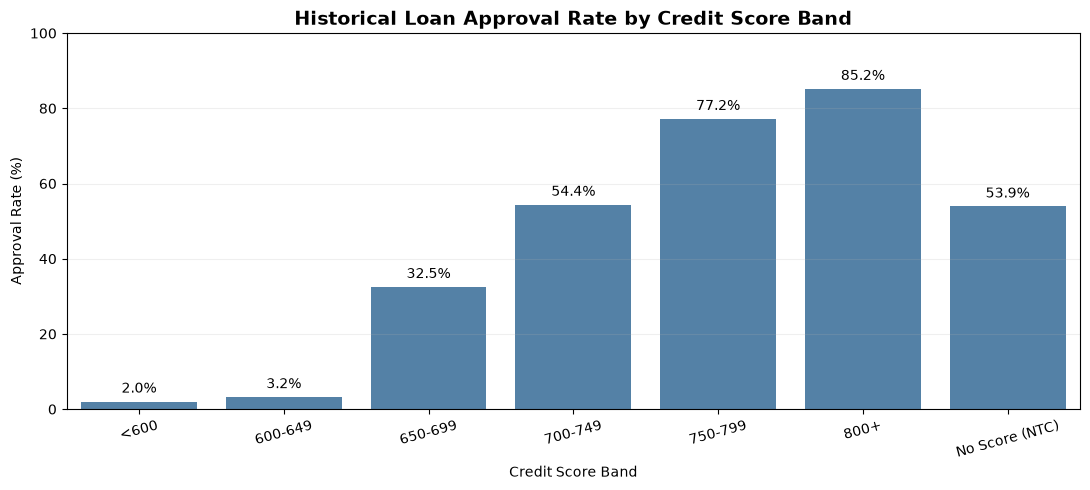

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

plot_data = score_summary.reset_index()

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=plot_data,
    x="credit_score_band",
    y="approval_rate_pct",
    color="steelblue"
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width()/2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Historical Loan Approval Rate by Credit Score Band",
          fontsize=14, weight="bold")
plt.xlabel("Credit Score Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


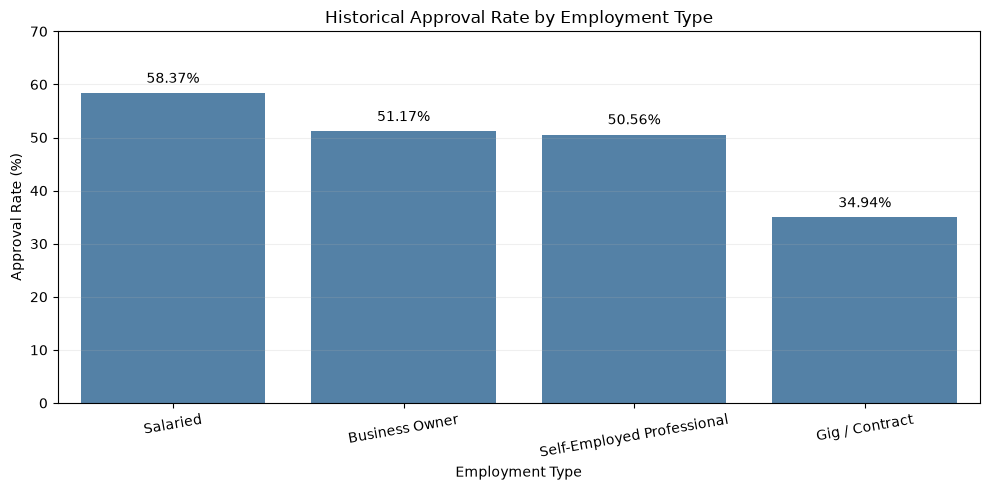

In [32]:
#Employment Type vs Historical Approval Rate

plot_data = (
    employment_summary
    .reset_index()
    .sort_values("approval_rate_pct", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_data,
    x="employment_type",
    y="approval_rate_pct",
    color="steelblue",
    ax=ax
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set(
    title="Historical Approval Rate by Employment Type",
    xlabel="Employment Type",
    ylabel="Approval Rate (%)",
    ylim=(0, 70)
)

ax.grid(axis="y", alpha=0.2)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


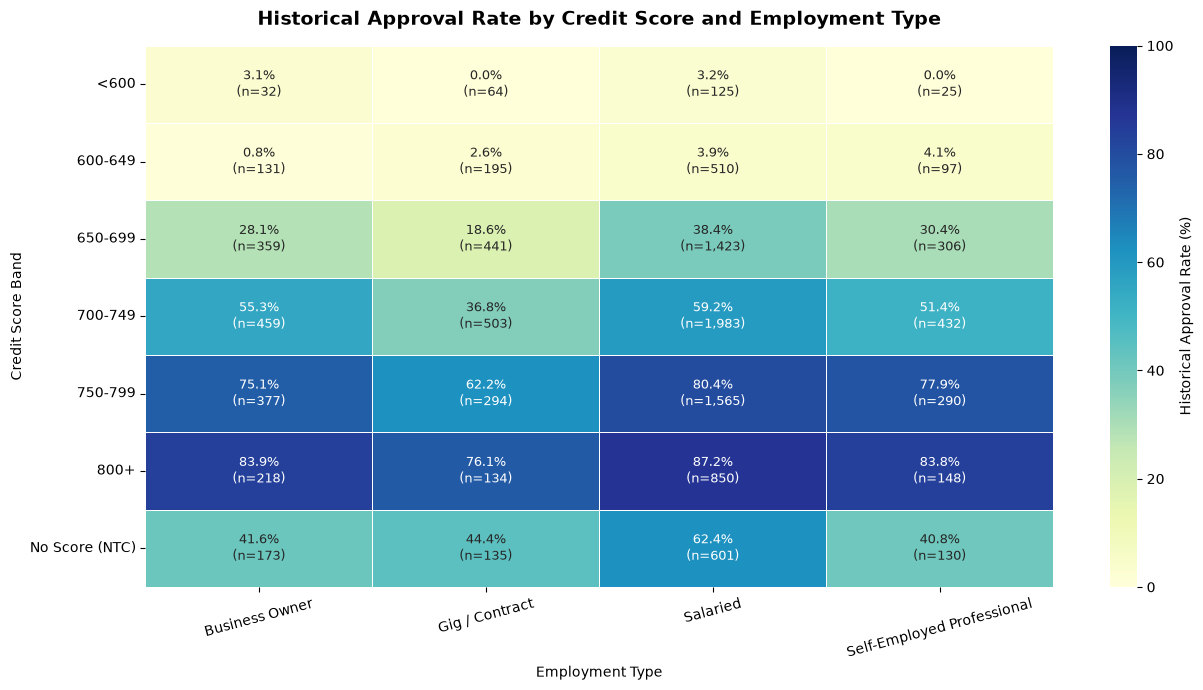

In [33]:

# Graph 3 — Credit Score × Employment Type Heatmap

# Prepare approval rates
rate_matrix = employment_credit_comparison.pivot(
    index="credit_score_band",
    columns="employment_type",
    values="approval_rate_pct"
)

# Prepare subgroup application counts
count_matrix = employment_credit_comparison.pivot(
    index="credit_score_band",
    columns="employment_type",
    values="applications"
)

# Create annotations: approval rate + sample size
annotations = rate_matrix.copy().astype(str)

for row in rate_matrix.index:
    for col in rate_matrix.columns:
        rate = rate_matrix.loc[row, col]
        count = count_matrix.loc[row, col]
        annotations.loc[row, col] = f"{rate:.1f}%\n(n={int(count):,})"

# Plot
fig, ax = plt.subplots(figsize=(13, 7))

sns.heatmap(
    rate_matrix,
    annot=annotations,
    fmt="",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"label": "Historical Approval Rate (%)"},
    annot_kws={"fontsize": 9},
    ax=ax
)

ax.set_title(
    "Historical Approval Rate by Credit Score and Employment Type",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Employment Type")
ax.set_ylabel("Credit Score Band")
ax.tick_params(axis="x", rotation=15)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


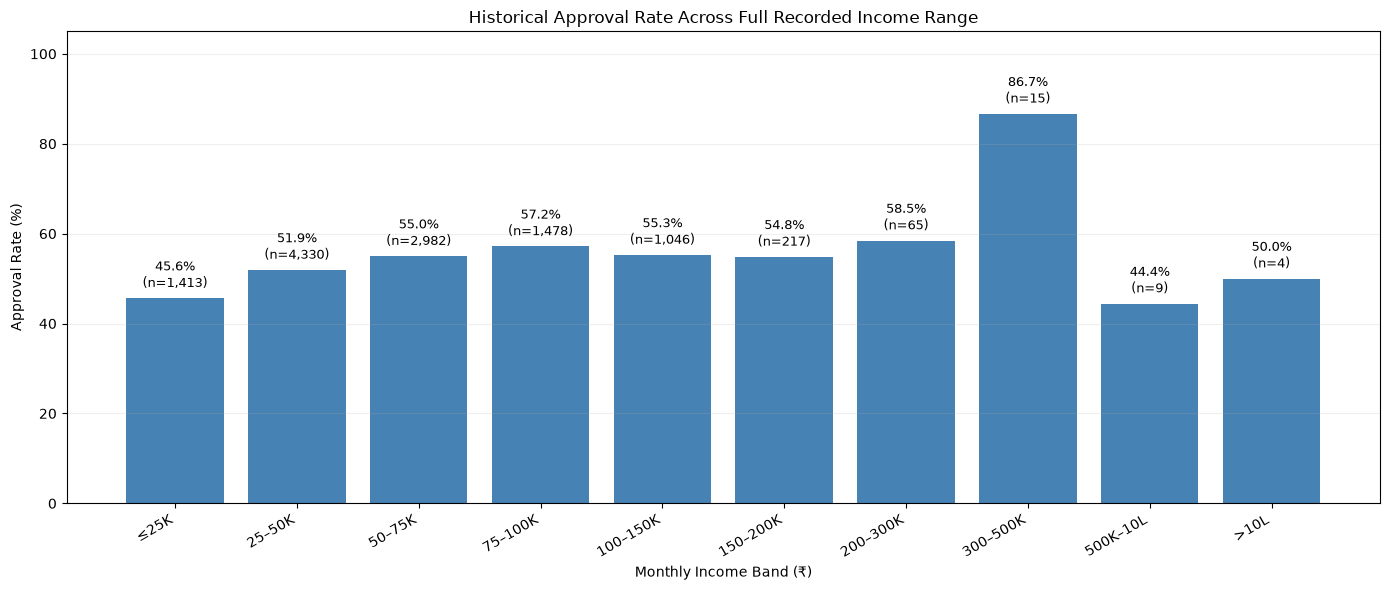

,applications,approved,approval_rate_pct
income_band,,,
≤25K,1413,645,45.647558
25–50K,4330,2248,51.916859
50–75K,2982,1640,54.996647
75–100K,1478,845,57.171854
100–150K,1046,578,55.258126
150–200K,217,119,54.838710
200–300K,65,38,58.461538
300–500K,15,13,86.666667
500K–10L,9,4,44.444444


In [36]:

# Full income range, including extreme values

income_bins = [
    0, 25000, 50000, 75000, 100000,
    150000, 200000, 300000, 500000,
    1000000, float("inf")
]

income_labels = [
    "≤25K", "25–50K", "50–75K", "75–100K",
    "100–150K", "150–200K", "200–300K",
    "300–500K", "500K–10L", ">10L"
]

income_eda = df_52.copy()

income_eda["income_band"] = pd.cut(
    income_eda["monthly_income"],
    bins=income_bins,
    labels=income_labels,
    include_lowest=True
)

income_summary = (
    income_eda.groupby("income_band", observed=False)["decision"]
    .agg(
        applications="size",
        approved=lambda x: (x == "Approved").sum()
    )
)

income_summary["approval_rate_pct"] = (
    income_summary["approved"]
    .div(income_summary["applications"].replace(0, float("nan")))
    .mul(100)
)

fig, ax = plt.subplots(figsize=(14, 6))

bars = ax.bar(
    range(len(income_summary)),
    income_summary["approval_rate_pct"].fillna(0),
    color="steelblue"
)

for bar, (_, row) in zip(bars, income_summary.iterrows()):
    if row["applications"] == 0:
        label = "No data"
    else:
        label = (
            f'{row["approval_rate_pct"]:.1f}%\n'
            f'(n={int(row["applications"]):,})'
        )

    ax.annotate(
        label,
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set_xticks(range(len(income_summary)))
ax.set_xticklabels(income_labels, rotation=30, ha="right")
ax.set_ylim(0, 105)
ax.set_title("Historical Approval Rate Across Full Recorded Income Range")
ax.set_xlabel("Monthly Income Band (₹)")
ax.set_ylabel("Approval Rate (%)")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

display(income_summary)


In [37]:

# Investigate applicants with recorded monthly income > ₹5 lakh

extreme_income = df_52.loc[
    df_52["monthly_income"] > 500000
].copy()

extreme_income["foir_recorded_pct"] = (
    (extreme_income["existing_emi"] +
     extreme_income["proposed_emi"])
    / extreme_income["monthly_income"] * 100
).round(2)

# Hypothetical FOIR if recorded income is annual
extreme_income["foir_if_annual_pct"] = (
    (extreme_income["existing_emi"] +
     extreme_income["proposed_emi"])
    / (extreme_income["monthly_income"] / 12) * 100
).round(2)

display(
    extreme_income[
        [
            "application_id",
            "employment_type",
            "monthly_income",
            "credit_score",
            "existing_emi",
            "proposed_emi",
            "foir_recorded_pct",
            "foir_if_annual_pct",
            "decision"
        ]
    ].sort_values("monthly_income", ascending=False)
)

print("Total extreme-income applicants:", len(extreme_income))
print(extreme_income["decision"].value_counts())


,application_id,employment_type,monthly_income,credit_score,existing_emi,proposed_emi,foir_recorded_pct,foir_if_annual_pct,decision
1467,APP101468,Salaried,1656000.0,718.0,16500.0,44400.0,3.68,44.13,Declined
300,APP100301,Salaried,1254000.0,NaN,0.0,6600.0,0.53,6.32,Approved
2493,APP102494,Salaried,1212000.0,718.0,23500.0,14000.0,3.09,37.13,Approved
589,APP100590,Salaried,1068000.0,700.0,13500.0,14000.0,2.57,30.90,Declined
9849,APP109850,Salaried,990000.0,633.0,21000.0,12500.0,3.38,40.61,Declined
1848,APP101849,Salaried,984000.0,NaN,0.0,17100.0,1.74,20.85,Approved
2488,APP102489,Salaried,972000.0,695.0,0.0,10600.0,1.09,13.09,Approved
4010,APP104011,Salaried,900000.0,789.0,4000.0,19800.0,2.64,31.73,Approved
4898,APP104899,Salaried,870000.0,682.0,4500.0,15000.0,2.24,26.90,Declined
9261,APP109262,Salaried,702000.0,740.0,0.0,16900.0,2.41,28.89,Approved


Total extreme-income applicants: 13
decision
Declined    7
Approved    6
Name: count, dtype: int64


In [38]:
# Flag unusually high Salaried incomes for investigation.
# ₹500,000 is an exploratory threshold, not a verified error rule.

df_clean["high_salaried_income_flag"] = (
    (df_clean["employment_type"] == "Salaried")
    & (df_clean["monthly_income"] > 500000)
).astype(int)

print("Flagged records:", df_clean["high_salaried_income_flag"].sum())

display(
    df_clean.loc[
        df_clean["high_salaried_income_flag"] == 1,
        ["application_id", "monthly_income", "decision"]
    ]
)

Flagged records: 13


,application_id,monthly_income,decision
300,APP100301,1254000.0,Approved
589,APP100590,1068000.0,Declined
595,APP100596,546000.0,Declined
1467,APP101468,1656000.0,Declined
1848,APP101849,984000.0,Approved
2488,APP102489,972000.0,Approved
2493,APP102494,1212000.0,Approved
4010,APP104011,900000.0,Approved
4898,APP104899,870000.0,Declined
7426,APP107427,690000.0,Declined


In [39]:

# Hypothesis investigation — Extreme salaried income records

salaried = df_clean.loc[
    df_clean["employment_type"] == "Salaried"
].copy()

salaried["income_group"] = (
    salaried["monthly_income"]
    .gt(500000)
    .map({
        True: "Extreme (>5L)",
        False: "Other salaried"
    })
)

features = [
    "monthly_income",
    "credit_score",
    "existing_emi",
    "proposed_emi",
    "loan_amount",
    "delinquencies_24m",
    "years_in_current_job"
]

comparison = (
    salaried.groupby("income_group")[features]
    .median()
    .T
)

display(comparison.round(2))

print("\nApplication counts:")
print(salaried["income_group"].value_counts())

print("\nHistorical decision breakdown:")
display(
    pd.crosstab(
        salaried["income_group"],
        salaried["decision"],
        normalize="index"
    ).mul(100).round(2)
)


income_group,Extreme (>5L),Other salaried
monthly_income,972000.0,50000.0
credit_score,697.5,729.0
existing_emi,4000.0,4000.0
proposed_emi,14400.0,10500.0
loan_amount,495000.0,295000.0
delinquencies_24m,0.0,0.0
years_in_current_job,3.9,3.3



Application counts:
income_group
Other salaried    7044
Extreme (>5L)       13
Name: count, dtype: int64

Historical decision breakdown:


decision,Approved,Declined
income_group,,
Extreme (>5L),46.15,53.85
Other salaried,58.39,41.61


In [40]:

# Diagnostic: Compare income interpretations for the 13 cases

income_diagnostic = extreme_income[
    [
        "application_id",
        "monthly_income",
        "credit_score",
        "foir_recorded_pct",
        "foir_if_annual_pct",
        "decision"
    ]
].copy()

income_diagnostic["income_if_annual_monthly"] = (
    income_diagnostic["monthly_income"] / 12
)

display(
    income_diagnostic.sort_values(
        "foir_if_annual_pct", ascending=False
    ).round(2)
)


,application_id,monthly_income,credit_score,foir_recorded_pct,foir_if_annual_pct,decision,income_if_annual_monthly
1467,APP101468,1656000.0,718.0,3.68,44.13,Declined,138000.0
9849,APP109850,990000.0,633.0,3.38,40.61,Declined,82500.0
2493,APP102494,1212000.0,718.0,3.09,37.13,Approved,101000.0
595,APP100596,546000.0,601.0,2.84,34.07,Declined,45500.0
4010,APP104011,900000.0,789.0,2.64,31.73,Approved,75000.0
589,APP100590,1068000.0,700.0,2.57,30.90,Declined,89000.0
9261,APP109262,702000.0,740.0,2.41,28.89,Approved,58500.0
7426,APP107427,690000.0,676.0,2.41,28.87,Declined,57500.0
8381,APP108382,618000.0,NaN,2.33,27.96,Declined,51500.0
4898,APP104899,870000.0,682.0,2.24,26.90,Declined,72500.0


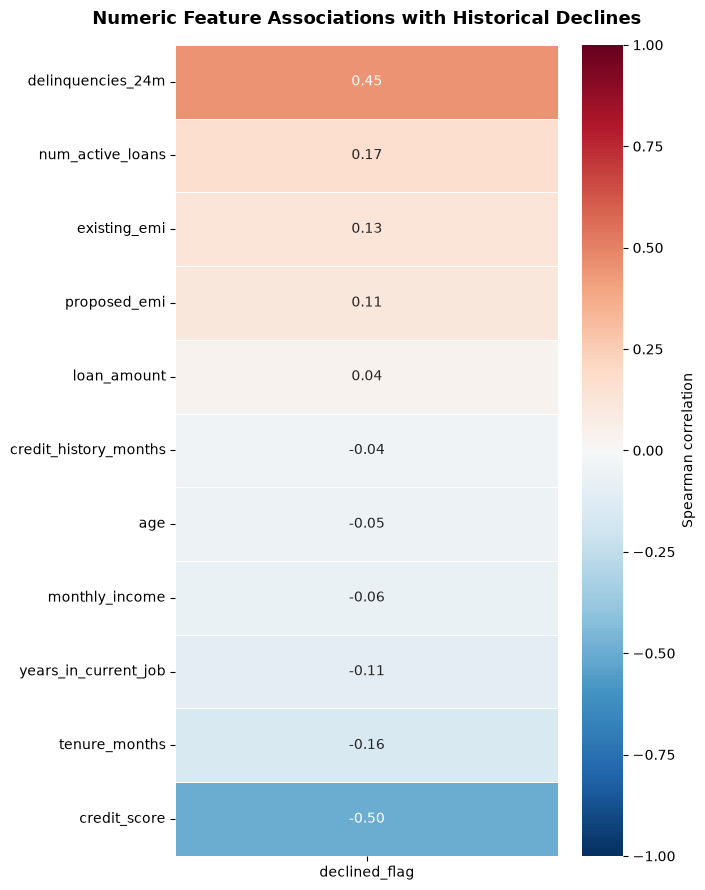

In [ ]:

# Numeric Feature Associations with Historical Decisions

eda_corr = df_52.copy()

# Target encoding ONLY for EDA, not model training
eda_corr["declined_flag"] = (
    eda_corr["decision"] == "Declined"
).astype(int)

numeric_features = [
    "age",
    "monthly_income",
    "existing_emi",
    "credit_score",
    "credit_history_months",
    "num_active_loans",
    "delinquencies_24m",
    "years_in_current_job",
    "loan_amount",
    "tenure_months",
    "proposed_emi"
]

# Use numeric features that actually exist in the dataset
numeric_features = [
    col for col in numeric_features
    if col in eda_corr.columns
]

correlation_matrix = eda_corr[
    numeric_features + ["declined_flag"]
].corr(method="spearman")

# Focus on relationships with the target
target_corr = (
    correlation_matrix[["declined_flag"]]
    .drop(index="declined_flag")
    .sort_values("declined_flag", ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 9))

sns.heatmap(
    target_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"},
    ax=ax
)

ax.set_title(
    "Numeric Feature Associations with Historical Declines",
    fontsize=13,
    weight="bold",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


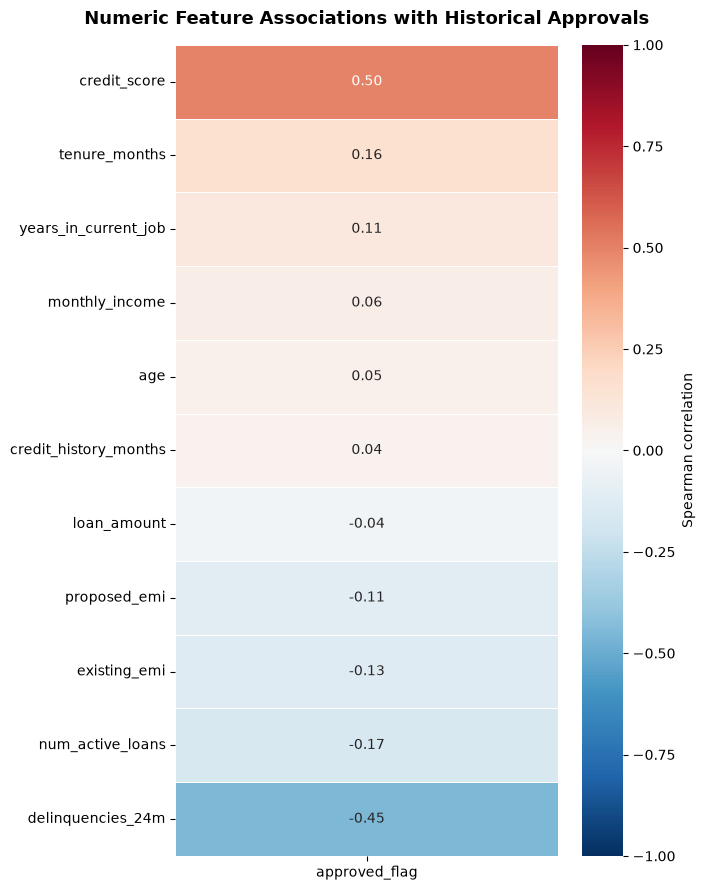

In [42]:

# — Numeric Feature Associations with Historical Decisions

eda_corr = df_52.copy()

# Target encoding ONLY for EDA, not model training
eda_corr["approved_flag"] = (
    eda_corr["decision"] == "Approved"
).astype(int)

numeric_features = [
    "age",
    "monthly_income",
    "existing_emi",
    "credit_score",
    "credit_history_months",
    "num_active_loans",
    "delinquencies_24m",
    "years_in_current_job",
    "loan_amount",
    "tenure_months",
    "proposed_emi"
]

# Use numeric features that actually exist in the dataset
numeric_features = [
    col for col in numeric_features
    if col in eda_corr.columns
]

correlation_matrix = eda_corr[
    numeric_features + ["approved_flag"]
].corr(method="spearman")

# Focus on relationships with the target
target_corr = (
    correlation_matrix[["approved_flag"]]
    .drop(index="approved_flag")
    .sort_values("approved_flag", ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 9))

sns.heatmap(
    target_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"},
    ax=ax
)

ax.set_title(
    "Numeric Feature Associations with Historical Approvals",
    fontsize=13,
    weight="bold",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


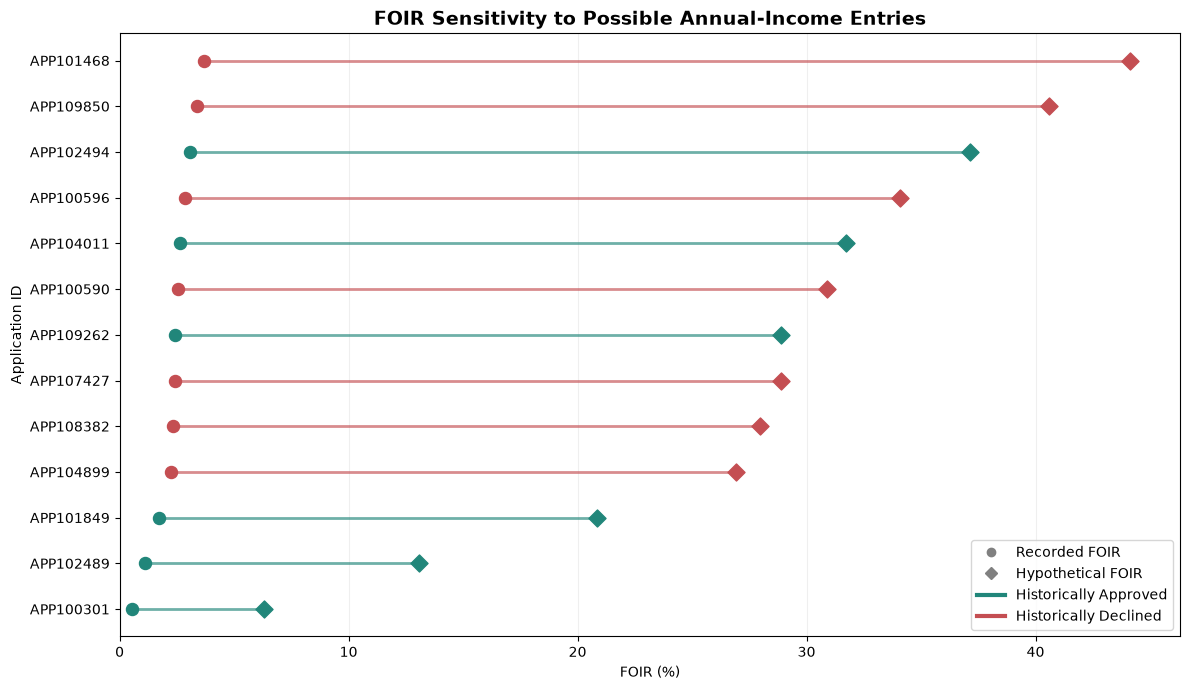

In [43]:

# Extreme Income Hypothesis: FOIR Sensitivity

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plot_df = extreme_income[
    ["application_id", "foir_recorded_pct",
     "foir_if_annual_pct", "decision"]
].copy()

plot_df = plot_df.sort_values(
    "foir_if_annual_pct"
).reset_index(drop=True)

colors = {
    "Approved": "#21867A",
    "Declined": "#C44E52"
}

fig, ax = plt.subplots(figsize=(12, 7))

for i, row in plot_df.iterrows():
    color = colors[row["decision"]]

    # Connect the two income interpretations
    ax.plot(
        [row["foir_recorded_pct"], row["foir_if_annual_pct"]],
        [i, i],
        color=color,
        linewidth=2,
        alpha=0.65
    )

    # Recorded FOIR: circle
    ax.scatter(
        row["foir_recorded_pct"], i,
        color=color, marker="o", s=75, zorder=3
    )

    # Hypothetical FOIR: diamond
    ax.scatter(
        row["foir_if_annual_pct"], i,
        color=color, marker="D", s=75, zorder=3
    )

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["application_id"])
ax.set_xlabel("FOIR (%)")
ax.set_ylabel("Application ID")
ax.set_title(
    "FOIR Sensitivity to Possible Annual-Income Entries",
    fontsize=14, fontweight="bold"
)

legend_items = [
    Line2D([0], [0], marker="o", color="gray",
           linestyle="None", label="Recorded FOIR"),
    Line2D([0], [0], marker="D", color="gray",
           linestyle="None", label="Hypothetical FOIR"),
    Line2D([0], [0], color=colors["Approved"],
           linewidth=3, label="Historically Approved"),
    Line2D([0], [0], color=colors["Declined"],
           linewidth=3, label="Historically Declined")
]

ax.legend(handles=legend_items, loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_xlim(left=0)

plt.tight_layout()
plt.show()


,applications,approved,approval_rate_pct
foir_band,,,
0–20%,2501,1637,65.45
20–30%,2824,1861,65.90
30–40%,2461,1458,59.24
40–50%,1655,788,47.61
50–60%,888,217,24.44
60–70%,491,58,11.81
70–100%,624,93,14.90
>100%,115,20,17.39


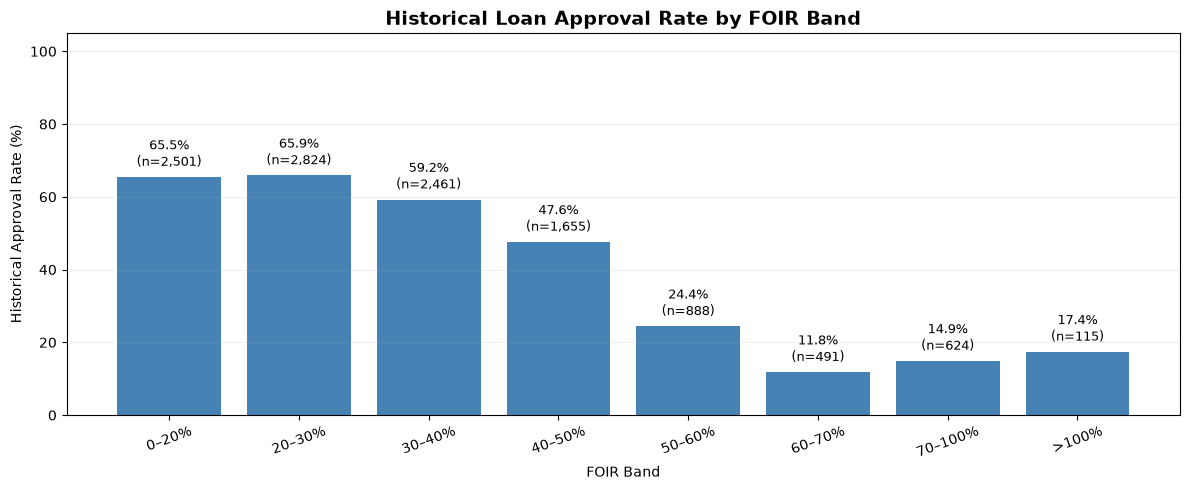

In [44]:

# FOIR vs Historical Approval Rate

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

foir_eda = df_52.copy()

# Calculate FOIR using recorded income
foir_eda["foir_pct"] = (
    (foir_eda["existing_emi"] + foir_eda["proposed_emi"])
    / foir_eda["monthly_income"] * 100
)

# Keep rows with valid recorded income and finite FOIR
foir_eda = foir_eda[
    foir_eda["foir_pct"].notna()
    & np.isfinite(foir_eda["foir_pct"])
    & (foir_eda["monthly_income"] > 0)
].copy()

# FOIR bands in percentage units
foir_bins = [0, 20, 30, 40, 50, 60, 70, 100, np.inf]
foir_labels = [
    "0–20%", "20–30%", "30–40%", "40–50%",
    "50–60%", "60–70%", "70–100%", ">100%"
]

foir_eda["foir_band"] = pd.cut(
    foir_eda["foir_pct"],
    bins=foir_bins,
    labels=foir_labels,
    include_lowest=True
)

foir_summary = (
    foir_eda.groupby("foir_band", observed=False)["decision"]
    .agg(
        applications="size",
        approved=lambda x: (x == "Approved").sum()
    )
)

foir_summary["approval_rate_pct"] = (
    foir_summary["approved"]
    .div(foir_summary["applications"].replace(0, np.nan))
    .mul(100)
)

display(foir_summary.round(2))

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    foir_summary.index.astype(str),
    foir_summary["approval_rate_pct"].fillna(0),
    color="steelblue"
)

for bar, (_, row) in zip(bars, foir_summary.iterrows()):
    label = (
        f'{row["approval_rate_pct"]:.1f}%\n(n={int(row["applications"]):,})'
        if row["applications"] > 0 else "No data"
    )

    ax.annotate(
        label,
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set_title(
    "Historical Loan Approval Rate by FOIR Band",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("FOIR Band")
ax.set_ylabel("Historical Approval Rate (%)")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


## 5.2 — Historical Approval Pattern Analysis: Findings and Conclusions

### 5.2.1 Objective

Investigate how applicant characteristics relate to historical loan decisions, identify potential unwritten credit-screening patterns, and evaluate suspicious income observations before building the predictive model.

**Dataset:** 12,000 applications  
**Historical approvals:** 6,353 (52.94%)  
**Historical declines:** 5,647 (47.06%)

Approval rates are calculated **within each group**, rather than against all 12,000 applications.

### 5.2.2 Credit Score Analysis

Historical approval rates rise substantially with credit score:

| Credit score | Applications | Approval rate |
|---|---:|---:|
| <600 | 246 | 2.03% |
| 600–649 | 933 | 3.22% |
| 650–699 | 2,529 | 32.50% |
| 700–749 | 3,377 | 54.37% |
| 750–799 | 2,526 | 77.20% |
| 800+ | 1,350 | 85.19% |
| No Score (NTC) | 1,039 | 53.90% |

**Findings:**
- Approval rates increase substantially with credit score, with a notable change around 650.
- Even among applicants scoring 800+, 200 were historically declined, indicating that credit score alone does not explain decisions.
- NTC applicants have a 53.90% approval rate and must not automatically be treated as high-risk.
- Missing credit scores were preserved as a separate NTC category during EDA rather than imputed.

**Interpretation:** Credit score appears strongly associated with historical decisions, but the observed patterns do not establish official bank policy thresholds.

### 5.2.3 Employment Type Analysis

| Employment type | Applications | Approval rate |
|---|---:|---:|
| Salaried | 7,057 | 58.37% |
| Business Owner | 1,749 | 51.17% |
| Self-Employed Professional | 1,428 | 50.56% |
| Gig / Contract | 1,766 | 34.94% |

**Findings:**
- Salaried applicants have the highest historical approval rate.
- Gig / Contract applicants have the lowest approval rate.
- The approval-rate difference between Salaried and Gig / Contract applicants is **23.43 percentage points**.

The credit-score × employment heatmap reveals that this difference persists within several credit-score bands.

For example, among applicants scoring 700–749:
- Salaried: 59.25% approval (n=1,983)
- Gig / Contract: 36.78% approval (n=503)

**Interpretation:** Employment type remains associated with decisions within credit-score bands, but this does not establish an independent causal effect. Differences in affordability, delinquency history and other characteristics may contribute.

### 5.2.4 Income Distribution and Approval Patterns

Recorded monthly income was grouped into bands, including extreme values above ₹5 lakh.

**Findings:**
- Lower and middle-income bands generally have approval rates of approximately 45%–59%.
- The ₹3–5 lakh band shows 86.67% approval, but includes only 15 applicants.
- The ₹5–10 lakh band has 44.44% approval (n=9).
- The above-₹10 lakh band has 50% approval (n=4).

**Interpretation:** Higher recorded income does not consistently correspond to higher approval rates. Small subgroup sizes and potentially inconsistent income reporting limit the conclusions.

### 5.2.5 Extreme-Income Hypothesis Investigation

**Observation:** Thirteen Salaried applicants reported monthly incomes above ₹5,00,000.

**Hypothesis:** Some applicants may have entered annual salary values into a monthly-income field.

We investigated this hypothesis through individual application inspection, subgroup comparisons, FOIR sensitivity calculations and visualization.

**Comparison of median characteristics:**

| Feature | Extreme-income group | Other Salaried |
|---|---:|---:|
| Monthly income | ₹9,72,000 | ₹50,000 |
| Credit score | 697.5 | 729 |
| Existing EMI | ₹4,000 | ₹4,000 |
| Proposed EMI | ₹14,400 | ₹10,500 |
| Loan amount | ₹4,95,000 | ₹2,95,000 |
| Delinquencies | 0 | 0 |
| Years in current job | 3.9 | 3.3 |

**Historical decision comparison:**
- Extreme-income applicants: 6 approved, 7 declined (46.15% approval)
- Other Salaried applicants: 58.39% approval

The extreme-income group has much higher reported income without proportionately higher existing EMI obligations.

**FOIR sensitivity analysis:**

Two scenarios were compared:
1. FOIR using income exactly as recorded.
2. FOIR assuming the recorded value represented annual income and dividing it by 12.

Results:
- Recorded FOIR: 0.53%–3.68%
- Hypothetical annual-adjusted FOIR: 6.32%–44.13%
- Hypothetical monthly incomes: ₹45,500–₹1,38,000

The paired-point visualization demonstrates that the possible income-unit inconsistency would substantially affect affordability calculations.

**Conclusion:** The annual-income hypothesis is plausible but unverified. Historical outcomes do not conclusively distinguish genuine high earnings from incorrectly recorded salary units.

**Data-quality decision:**
- Retain original income values.
- Flag the 13 records for potential income verification.
- Do not divide incomes by 12, delete observations, or replace them without supporting evidence.
- Conduct modelling sensitivity analysis later to assess the impact of these observations.

### 5.2.6 Numeric Feature Associations with Historical Decisions

For exploratory correlation analysis, the target was encoded as:

- Approved = 0
- Declined = 1

Spearman rank correlation was used to examine monotonic associations between numerical characteristics and historical declines.

Selected results:

| Feature | Correlation with decline |
|---|---:|
| Credit score | −0.50 |
| Number of active loans | +0.17 |
| Existing EMI | +0.13 |
| Proposed EMI | +0.11 |
| Loan amount | +0.04 |
| Monthly income | −0.06 |
| Years in current job | −0.11 |
| Tenure months | −0.16 |

**Findings:**
- Credit score shows the strongest observed monotonic association among these listed features.
- Higher credit scores are associated with fewer historical declines.
- More active loans and higher EMI obligations show weaker positive associations with declines.
- Monthly income alone has a weak association with historical decisions.

**Limitation:** Correlation magnitude does not represent model feature importance, causal influence or percentage contribution to a decision. Categorical variables and complex feature interactions require separate analysis.

### 5.2.7 Exploratory FOIR Analysis

FOIR was introduced as an engineered affordability indicator:

**FOIR = (Existing EMI + Proposed EMI) / Monthly Income**

FOIR and loan-to-income ratios were temporarily calculated using available recorded incomes for exploratory analysis. Missing-income observations were not imputed at this stage.

A FOIR-band approval-rate chart was generated to examine the relationship between EMI burden and historical decisions.

**Working hypothesis:** Higher FOIR may be associated with lower historical approval rates.

The directional conclusion should be finalized after reviewing the actual FOIR-band approval-rate table. These exploratory calculations do not yet constitute the production feature-engineering pipeline.

### 5.2.8 Overall Business Findings and Decisions

**Major findings:**
1. Credit score is strongly associated with historical approval patterns.
2. Employment-related differences remain visible within credit-score bands.
3. Recorded income alone has limited explanatory power for historical decisions.
4. Thirteen high-income observations present an unresolved data-quality concern with potentially significant effects on affordability calculations.
5. Multiple applicant characteristics must be considered together to understand historical decisions.

**Decisions for the modelling phase:**
- Preserve the NTC indicator for applicants with missing credit scores.
- Fit missing-value imputers using training data only.
- Formally engineer FOIR and loan-to-income features in Step 5.3.
- Preserve original high-income records and document any sensitivity experiments.
- Evaluate decision disagreement, fairness and automation coverage on held-out data.

**Final limitation:** The target represents historical analyst approval/decline decisions, not actual loan repayment or default outcomes. The observed associations do not establish causation, official credit policy or independently verified borrower risk.

In [46]:

from src.features.engineering import CreditFeatureEngineer

# Apply feature engineering to a copy of the original dataset
feature_engineer = CreditFeatureEngineer()
df_features = feature_engineer.fit_transform(df_raw)

# Check newly created features
display(
    df_features[
        ["monthly_income", "existing_emi", "proposed_emi",
         "credit_score", "foir", "loan_to_income", "is_ntc"]
    ].head(10)
)

print("Dataset shape:", df_features.shape)
print("\nMissing engineered values:")
print(df_features[["foir", "loan_to_income", "is_ntc"]].isna().sum())

print("\nNTC applicants:", df_features["is_ntc"].sum())


,monthly_income,existing_emi,proposed_emi,credit_score,foir,loan_to_income,is_ntc
0,95000.0,23500.0,6600.0,784.0,0.316842,0.210526,0
1,43000.0,8500.0,5000.0,790.0,0.313953,0.281008,0
2,35000.0,3500.0,11800.0,718.0,0.437143,0.821429,0
3,44500.0,0.0,4600.0,NaN,0.103371,0.252809,1
4,83500.0,6000.0,33600.0,700.0,0.474251,0.698603,0
5,105000.0,6000.0,12100.0,808.0,0.172381,0.281746,0
6,30000.0,2000.0,14800.0,792.0,0.560000,0.458333,0
7,NaN,16500.0,37700.0,634.0,NaN,NaN,0
8,74500.0,19000.0,21800.0,738.0,0.547651,0.508949,0
9,NaN,5500.0,26700.0,687.0,NaN,NaN,0


Dataset shape: (12000, 22)

Missing engineered values:
foir              441
loan_to_income    441
is_ntc              0
dtype: int64

NTC applicants: 1039


In [47]:

import numpy as np

ratio_columns = ["foir", "loan_to_income"]

for col in ratio_columns:
    values = df_features[col]

    print(f"\n{col.upper()}")
    print("Negative values:", (values < 0).sum())
    print("Infinite values:", np.isinf(values).sum())
    print("Missing values:", values.isna().sum())
    print("Minimum:", values.min())
    print("Median:", values.median())
    print("Maximum:", values.max())

print("\nNTC flag values:")
print(df_features["is_ntc"].value_counts())



FOIR
Negative values: 0
Infinite values: 0
Missing values: 441
Minimum: 0.004797979797979798
Median: 0.3162303664921466
Maximum: 1.5051643192488262

LOAN_TO_INCOME
Negative values: 0
Infinite values: 0
Missing values: 441
Minimum: 0.014730639730639731
Median: 0.5191256830601093
Maximum: 1.0846560846560847

NTC flag values:
is_ntc
0    10961
1     1039
Name: count, dtype: int64


In [48]:

# Investigate applicants with FOIR above 100%

high_foir = df_features.loc[
    df_features["foir"] > 1
].copy()

print("Applicants with FOIR > 100%:", len(high_foir))

print("\nHistorical decisions:")
display(high_foir["decision"].value_counts())

display(
    high_foir[
        [
            "application_id",
            "monthly_income",
            "existing_emi",
            "proposed_emi",
            "foir",
            "credit_score",
            "decision"
        ]
    ].sort_values("foir", ascending=False).head(10)
)


Applicants with FOIR > 100%: 115

Historical decisions:


decision
Declined    95
Approved    20
Name: count, dtype: int64

,application_id,monthly_income,existing_emi,proposed_emi,foir,credit_score,decision
5931,APP105932,106500.0,39500.0,120800.0,1.505164,775.0,Declined
11328,APP111329,46000.0,17000.0,50700.0,1.471739,792.0,Declined
4202,APP104203,41500.0,12000.0,48000.0,1.445783,781.0,Declined
2138,APP102139,32000.0,16500.0,29200.0,1.428125,722.0,Declined
9173,APP109174,146500.0,80500.0,124400.0,1.398635,756.0,Declined
302,APP100303,56000.0,11500.0,62900.0,1.328571,745.0,Declined
5304,APP105305,61000.0,37000.0,43100.0,1.313115,775.0,Declined
2347,APP102348,57000.0,29500.0,44400.0,1.296491,725.0,Declined
6283,APP106284,24000.0,5000.0,25600.0,1.275000,802.0,Approved
183,APP100184,42000.0,4500.0,48500.0,1.261905,812.0,Approved


In [49]:
high_foir_summary = (
    high_foir["decision"]
    .value_counts()
    .reindex(["Approved", "Declined"], fill_value=0)
)

print("Total applicants:", len(high_foir))
print(high_foir_summary)

print(
    "Approval rate:",
    round(
        (high_foir["decision"] == "Approved").mean() * 100,
        2
    ),
    "%"
)

Total applicants: 115
decision
Approved    20
Declined    95
Name: count, dtype: int64
Approval rate: 17.39 %


## 5.3 — Feature Engineering: Findings and Validation

### Objective
Create reusable affordability and credit-history features to improve the representation of applicant characteristics for ML modelling.

### Engineered Features

| Feature | Definition | Purpose |
|---|---|---|
| `foir` | (Existing EMI + Proposed EMI) / Monthly Income | Measures EMI burden relative to income |
| `loan_to_income` | Loan Amount / (Monthly Income × 12) | Measures requested loan relative to annual income |
| `is_ntc` | 1 if credit score originally missing; otherwise 0 | Identifies applicants without a recorded credit score |

### Implementation and Testing
- Implemented `CreditFeatureEngineer` in `src/features/engineering.py`.
- Created five unit tests covering feature calculations, NTC detection, zero/missing-income handling and input preservation.
- Applied the transformer to all 12,000 applications for exploratory validation.
- Dataset expanded from **19 to 22 columns**, preserving all applications.

### Validation Results

| Check | Result |
|---|---:|
| Median FOIR | 31.62% |
| Maximum FOIR | 150.52% |
| Median loan-to-income | 0.5191 |
| Maximum loan-to-income | 1.0847 |
| Missing FOIR / loan-to-income | 441 each |
| Missing NTC flags | 0 |
| NTC applicants | 1,039 |
| Negative or infinite ratios | 0 |

### High-FOIR Investigation
- Identified **115 applicants with FOIR above 100%**.
- Of these, **95 (82.61%) were historically declined** and **20 (17.39%) were approved**.
- This supports the observed association between high EMI burden and historical declines.
- High FOIR does not automatically imply incorrect data or guarantee a particular decision.

### Proposed FOIR Policy — Preliminary Recommendation

Historical approval rates decrease markedly as FOIR increases, particularly around 50%. The approval rate falls from 47.61% in the 40–50% band to 24.44% in the 50–60% band.

**Proposed policy:** Use approximately **50% FOIR as an affordability review trigger**, subject to further validation. Applications exceeding this level should receive additional affordability assessment rather than automatic rejection.

This is a provisional recommendation based on historical associations, not a confirmed bank policy. The exact 50–55% FOIR band and model-based decision thresholds must be evaluated before implementation.

### Engineering Decisions
- Preserve original income and credit-score values during EDA.
- Retain missing ratio values until leakage-safe income imputation.
- Fit employment-based income imputation using training data only.
- Calculate affordability ratios after income imputation.
- Preserve the original missing-credit-score indicator before credit-score imputation.
- Evaluate whether engineered features improve prediction using held-out data.

**Conclusion:** All three features have been implemented and validated for exploratory use. Their incremental predictive value remains to be tested during model development.

In [50]:

from sklearn.model_selection import train_test_split

# Start from original records.
# Feature engineering will be integrated into preprocessing.
model_df = df_raw.copy()

# Target: 1 = Declined, 0 = Approved
y = (model_df["decision"] == "Declined").astype(int)

# Exclude target and identifier/non-modelling columns
exclude_cols = [
    "decision",
    "application_id",
    "application_date",
    "city",
    "gender"
]

X = model_df.drop(columns=exclude_cols)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution (%):")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution (%):")
print(y_test.value_counts(normalize=True).mul(100).round(2))

print("\nShared application indices:",
      len(set(X_train.index) & set(X_test.index)))


Training shape: (9600, 14)
Testing shape: (2400, 14)

Training target distribution (%):
decision
0    52.94
1    47.06
Name: proportion, dtype: float64

Testing target distribution (%):
decision
0    52.96
1    47.04
Name: proportion, dtype: float64

Shared application indices: 0


In [51]:

from sklearn.pipeline import Pipeline

from src.data.imputation import EmploymentIncomeImputer
from src.features.engineering import CreditFeatureEngineer

# First impute income, then calculate engineered features.
# Credit scores remain missing until later preprocessing.
feature_pipeline = Pipeline(steps=[
    ("income_imputer", EmploymentIncomeImputer()),
    ("feature_engineer", CreditFeatureEngineer())
])

# Fit using TRAINING DATA ONLY
X_train_features = feature_pipeline.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Engineered training shape:", X_train_features.shape)

print("\nEngineered features:")
display(
    X_train_features[
        ["monthly_income", "credit_score",
         "is_ntc", "foir", "loan_to_income"]
    ].head()
)

print("\nMissing engineered values:")
print(
    X_train_features[
        ["monthly_income", "foir", "loan_to_income"]
    ].isna().sum()
)


Original training shape: (9600, 14)
Engineered training shape: (9600, 17)

Engineered features:


,monthly_income,credit_score,is_ntc,foir,loan_to_income
2236,79500.0,798.0,0,0.208805,0.193920
2403,52500.0,758.0,0,0.274286,0.777778
8286,26500.0,714.0,0,0.218868,0.440252
3654,28500.0,575.0,0,0.238596,0.584795
263,44000.0,693.0,0,0.154545,0.473485



Missing engineered values:
monthly_income    0
foir              0
loan_to_income    0
dtype: int64


In [52]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numeric features that require imputation and scaling
numeric_features = [
    "age",
    "credit_score",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "tenure_months"
]

# Categorical features
categorical_features = [
    "employment_type",
    "loan_purpose",
    "city_tier"
]

# Binary indicator already created by our feature engineer
binary_features = ["is_ntc"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
        ("binary", "passthrough", binary_features)
    ],
    remainder="drop"
)

# Fit preprocessing using engineered TRAINING data only
X_train_processed = preprocessor.fit_transform(X_train_features)

print("Processed training shape:", X_train_processed.shape)
print("Number of output features:", len(preprocessor.get_feature_names_out()))

print("\nOutput feature names:")
print(preprocessor.get_feature_names_out())


Processed training shape: (9600, 23)
Number of output features: 23

Output feature names:
['num__age' 'num__credit_score' 'num__foir' 'num__loan_to_income'
 'num__delinquencies_24m' 'num__num_active_loans'
 'num__years_in_current_job' 'num__tenure_months'
 'cat__employment_type_Business Owner'
 'cat__employment_type_Gig / Contract' 'cat__employment_type_Salaried'
 'cat__employment_type_Self-Employed Professional'
 'cat__loan_purpose_Consumer Durables'
 'cat__loan_purpose_Debt Consolidation' 'cat__loan_purpose_Education'
 'cat__loan_purpose_Home Renovation' 'cat__loan_purpose_Medical'
 'cat__loan_purpose_Travel' 'cat__loan_purpose_Wedding' 'cat__city_tier_1'
 'cat__city_tier_2' 'cat__city_tier_3' 'binary__is_ntc']


In [54]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from src.data.imputation import EmploymentIncomeImputer
from src.features.engineering import CreditFeatureEngineer

# Complete ML pipeline
logistic_model = Pipeline(steps=[
    ("income_imputer", EmploymentIncomeImputer()),

    ("feature_engineer", CreditFeatureEngineer()),

    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train using original training features
# The pipeline automatically imputes, scales and encodes
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

print(
    "Model input features:",
    logistic_model.named_steps["classifier"].n_features_in_
)

print(
    "Model classes:",
    logistic_model.named_steps["classifier"].classes_
)

print(
    "Training iterations:",
    logistic_model.named_steps["classifier"].n_iter_
)


Logistic Regression training completed!
Model input features: 23
Model classes: [0 1]
Training iterations: [15]


In [55]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Predict historical decisions on held-out test data
y_pred = logistic_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Decline Precision:", round(precision_score(y_test, y_pred), 4))
print("Decline Recall:", round(recall_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Approved", "Declined"]
))


Accuracy: 0.7896
Decline Precision: 0.7889
Decline Recall: 0.7547

Confusion Matrix:
[[1043  228]
 [ 277  852]]

Classification Report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



In [57]:



# Extract trained model components
trained_preprocessor = logistic_model.named_steps["preprocessor"]
trained_classifier = logistic_model.named_steps["classifier"]

# Extract feature names and coefficients
feature_names = trained_preprocessor.get_feature_names_out()
coefficients = trained_classifier.coef_[0]

# Create coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute_Importance"] = coef_df["Coefficient"].abs()

# Sort by absolute coefficient
coef_df = coef_df.sort_values(
    "Absolute_Importance",
    ascending=False
)

print("Top 10 Logistic Regression Coefficients:")
display(coef_df.head(10))


Top 10 Logistic Regression Coefficients:


,Feature,Coefficient,Absolute_Importance
22,binary__is_ntc,1.340357,1.340357
2,num__foir,1.223179,1.223179
1,num__credit_score,-1.008649,1.008649
4,num__delinquencies_24m,0.979240,0.979240
9,cat__employment_type_Gig / Contract,0.594417,0.594417
10,cat__employment_type_Salaried,-0.465634,0.465634
13,cat__loan_purpose_Debt Consolidation,0.342079,0.342079
3,num__loan_to_income,-0.198116,0.198116
12,cat__loan_purpose_Consumer Durables,-0.169460,0.169460
6,num__years_in_current_job,-0.144994,0.144994


## Step 5.4 — Logistic Regression Baseline: Results & Business Interpretation

### Model Performance

A Logistic Regression classifier was trained using an 80/20 stratified train-test split. The model achieved **78.96% accuracy**, **78.89% decline precision**, and **75.47% decline recall** on 2,400 test applications.

### Confusion Matrix — Business Interpretation

- **1,043** historically approved applications were correctly predicted as Approved.
- **852** historically declined applications were correctly predicted as Declined.
- **228** historically approved applications were incorrectly predicted as Declined.
- **277** historically declined applications were incorrectly predicted as Approved.

At the default 0.50 classification threshold, the model would incorrectly flag **228 historically approved applicants for decline**. This creates a risk of rejecting potentially valuable customers, making the baseline unsuitable for direct automated lending decisions.

### Key Factors Influencing Decline Predictions

The five largest coefficients by absolute magnitude were:

| Feature | Coefficient | Interpretation |
|---|---:|---|
| New-to-credit indicator | +1.340 | Applicants without a recorded credit score receive a positive contribution toward predicted decline. |
| FOIR | +1.223 | Higher repayment obligations relative to income increase predicted decline risk. |
| Credit score | −1.009 | Higher credit scores reduce predicted decline risk. |
| Delinquencies (24 months) | +0.979 | More recent delinquencies increase predicted decline risk. |
| Gig / Contract employment | +0.594 | This employment category contributes positively toward predicted decline. |

These coefficients represent learned associations with historical credit decisions, not causal effects or actual repayment/default risk. Numerical coefficients reflect standardized inputs; the new-to-credit and employment indicators are binary.

### Conclusion

The baseline identifies meaningful historical lending patterns, particularly affordability, credit history, and repayment behaviour. However, its **21.11% disagreement rate among predicted declines** exceeds the bank's maximum permitted **5% error within the auto-decline lane**. Therefore, the next step is to evaluate stricter probability thresholds before recommending automation.

In [58]:

import numpy as np
import pandas as pd

# Get the probability of Declined (class 1)
p_decline = logistic_model.predict_proba(X_test)[:, 1]

thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:
    auto_decline = p_decline >= threshold

    total_auto_declined = auto_decline.sum()

    wrong_declines = (
        auto_decline & (y_test.to_numpy() == 0)
    ).sum()

    disagreement_rate = (
        wrong_declines / total_auto_declined
        if total_auto_declined > 0 else np.nan
    )

    coverage = total_auto_declined / len(y_test)

    results.append({
        "Threshold": threshold,
        "Auto_Declined": total_auto_declined,
        "Wrong_Declines": wrong_declines,
        "Disagreement_%": round(disagreement_rate * 100, 2),
        "Coverage_%": round(coverage * 100, 2),
        "Meets_5%_Rule": (
            disagreement_rate <= 0.05
            if total_auto_declined > 0 else False
        )
    })

threshold_df = pd.DataFrame(results)

display(threshold_df)


,Threshold,Auto_Declined,Wrong_Declines,Disagreement_%,Coverage_%,Meets_5%_Rule
0,0.50,1080,228,21.11,45.00,False
1,0.60,900,150,16.67,37.50,False
2,0.70,739,88,11.91,30.79,False
3,0.80,567,42,7.41,23.62,False
4,0.85,475,29,6.11,19.79,False
5,0.90,360,16,4.44,15.00,True
6,0.95,238,5,2.10,9.92,True


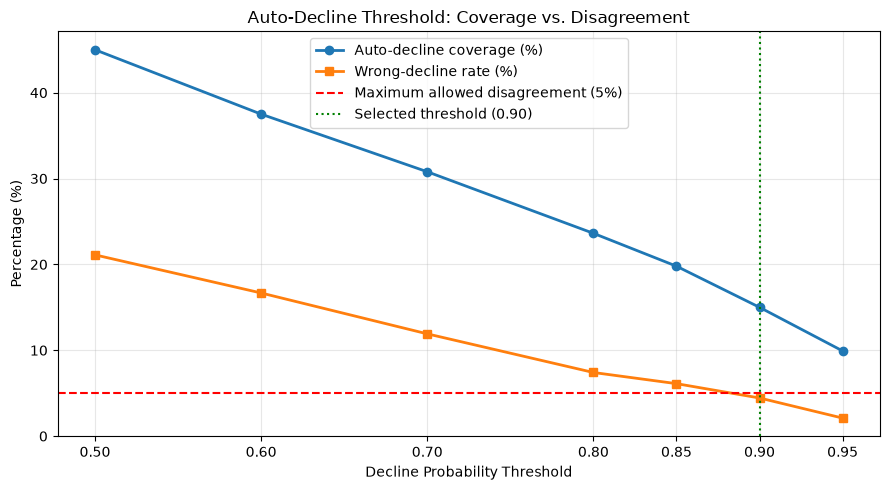

In [59]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Coverage_%"],
    marker="o",
    linewidth=2,
    label="Auto-decline coverage (%)"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Disagreement_%"],
    marker="s",
    linewidth=2,
    label="Wrong-decline rate (%)"
)

plt.axhline(
    y=5,
    color="red",
    linestyle="--",
    label="Maximum allowed disagreement (5%)"
)

plt.axvline(
    x=0.90,
    color="green",
    linestyle=":",
    label="Selected threshold (0.90)"
)

plt.xlabel("Decline Probability Threshold")
plt.ylabel("Percentage (%)")
plt.title("Auto-Decline Threshold: Coverage vs. Disagreement")
plt.xticks(threshold_df["Threshold"])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Step 5.5 — Auto-Decline Threshold Selection

The baseline model's default 0.50 threshold produced a **21.11% historical disagreement rate** among predicted declines, exceeding the bank's 5% limit.

**Recommended provisional threshold: 0.90**

At this threshold:
- **360 of 2,400 applications (15%)** qualify for auto-decline.
- **344** were historically declined, while **16** were historically approved.
- Historical disagreement falls to **4.44%**, satisfying the 5% requirement on the test sample.
- The remaining **2,040 applications** are routed to manual review, not automatically approved.

A threshold of 0.95 also meets the limit but reduces automation coverage to 9.92%. Therefore, **0.90 provides the highest coverage among the tested thresholds that satisfy the constraint**.

**Estimated monthly business impact:** With 3,000 applications per month, 15% coverage could automate approximately **450 declines**, avoiding **187.5 analyst review-hours per month** at 25 minutes per application.

**Limitation:** This threshold was selected using the test results and requires independent validation before deployment. Historical agreement also does not establish actual loan repayment risk.

In [60]:

# Historical approval rate by gender
gender_summary = (
    df_raw.groupby("gender")["decision"]
    .agg(
        Applications="count",
        Approval_Rate=lambda x: (x == "Approved").mean() * 100
    )
    .round(2)
)

print("Overall historical approval rates:")
display(gender_summary)

# Approval rates by gender and employment
gender_employment = pd.crosstab(
    [df_raw["employment_type"], df_raw["gender"]],
    df_raw["decision"],
    normalize="index"
).mul(100).round(2)

print("Approval rates by gender within employment categories:")
display(gender_employment)


Overall historical approval rates:


,Applications,Approval_Rate
gender,,
Female,3795,50.43
Male,8205,54.10


Approval rates by gender within employment categories:


decision                           Approved  Declined
employment_type            gender                    
Business Owner             Female     51.62     48.38
                           Male       51.05     48.95
Gig / Contract             Female     34.65     65.35
                           Male       35.18     64.82
Salaried                   Female     56.79     43.21
                           Male       59.06     40.94
Self-Employed Professional Female     47.63     52.37
                           Male       51.97     48.03

In [61]:

gender_income_employment = (
    df_raw.groupby("gender")
    .agg(
        Applications=("gender", "size"),
        Median_Monthly_Income=("monthly_income", "median"),
        Gig_Contract_Share=(
            "employment_type",
            lambda x: (x == "Gig / Contract").mean() * 100
        )
    )
    .round(2)
)

display(gender_income_employment)


,Applications,Median_Monthly_Income,Gig_Contract_Share
gender,,,
Female,3795,44000.0,21.37
Male,8205,54000.0,11.64


In [62]:

# Use the same test rows used for model evaluation
fairness_df = df_raw.loc[X_test.index, ["gender"]].copy()

# Add actual historical decision and model probability
fairness_df["actual_declined"] = y_test
fairness_df["decline_probability"] = logistic_model.predict_proba(X_test)[:, 1]

# Apply selected auto-decline threshold
fairness_df["auto_declined"] = (
    fairness_df["decline_probability"] >= 0.90
)

# Compare auto-decline rates by gender
gender_auto_decline = (
    fairness_df.groupby("gender")
    .agg(
        Applications=("gender", "size"),
        Auto_Declined=("auto_declined", "sum"),
        Auto_Decline_Rate=(
            "auto_declined",
            lambda x: x.mean() * 100
        )
    )
    .round(2)
)

display(gender_auto_decline)


,Applications,Auto_Declined,Auto_Decline_Rate
gender,,,
Female,750,118,15.73
Male,1650,242,14.67


In [63]:

# Wrong auto-declines among historically approved applications
approved_cases = fairness_df[
    fairness_df["actual_declined"] == 0
].copy()

gender_error_audit = (
    approved_cases.groupby("gender")
    .agg(
        Historically_Approved=("gender", "size"),
        Wrong_Auto_Declines=("auto_declined", "sum"),
        Wrong_Decline_Rate=(
            "auto_declined",
            lambda x: x.mean() * 100
        )
    )
    .round(2)
)

display(gender_error_audit)


,Historically_Approved,Wrong_Auto_Declines,Wrong_Decline_Rate
gender,,,
Female,377,5,1.33
Male,894,11,1.23


### Step 5.6 — Gender Fairness Audit

Historical approval rates were **50.43% for female applicants** and **54.10% for male applicants**, a gap of 3.67 percentage points. Female applicants had a lower median monthly income (₹44,000 vs ₹54,000) and a higher share of Gig/Contract employment (21.37% vs 11.64%), which may partly explain the historical gap, although causation has not been established.

At the selected 0.90 threshold, the model auto-declined **15.73% of female applicants** and **14.67% of male applicants**. Among historically approved applicants, incorrect auto-decline rates were **1.33% for females** and **1.23% for males**, indicating a small observed disparity.

The model does not appear to substantially widen the gender gap in auto-decline rates, but these descriptive comparisons do not establish that it is fair or determine its effect on the historical approval gap. Gender should not be used as a direct creditworthiness predictor without appropriate legal and regulatory justification, and excluding it does not eliminate potential bias because other features may act as proxies.

**Conclusion:** The initial fairness audit shows relatively small differences in model auto-decline outcomes, but additional validation is required before deployment.

## Step 5.7 — Interim Briefing

The Logistic Regression baseline achieved **78.96% accuracy**, with a recommended provisional auto-decline threshold of **0.90**, resulting in **4.44% historical disagreement** among auto-declined applications. This threshold covers **15% of applications**, potentially automating **450 applications per month** and saving approximately **187.5 analyst review-hours**, assuming 3,000 monthly applications and 25 minutes per review. The fairness audit identified a relatively small gender difference in auto-decline rates (15.73% female versus 14.67% male), although further validation is required. The main weakness to address in Part 2 is **limited automation coverage**, so we will compare stronger models and introduce a separate fast-track approval lane while maintaining the 5% disagreement limit for each automated lane.

In [64]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# Predict directly from the 14 original test features
pipeline_predictions = logistic_model.predict(X_test)

print("Pipeline Baseline Verification")
print("-" * 35)

print("Accuracy:",
      round(accuracy_score(y_test, pipeline_predictions), 4))

print("Decline Precision:",
      round(precision_score(y_test, pipeline_predictions), 4))

print("Decline Recall:",
      round(recall_score(y_test, pipeline_predictions), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pipeline_predictions))

print("\nProcessed Input Features:",
      logistic_model.named_steps["classifier"].n_features_in_)


Pipeline Baseline Verification
-----------------------------------
Accuracy: 0.7896
Decline Precision: 0.7889
Decline Recall: 0.7547

Confusion Matrix:
[[1043  228]
 [ 277  852]]

Processed Input Features: 23


In [65]:

# Select the five most recent applications
recent_applications = (
    df_raw
    .assign(
        application_date=pd.to_datetime(
            df_raw["application_date"]
        )
    )
    .sort_values("application_date", ascending=False)
    .head(5)
    .copy()
)

# Keep raw input features; remove excluded columns
recent_X = recent_applications.drop(
    columns=[
        "application_id",
        "application_date",
        "city",
        "gender",
        "decision"
    ]
)

# Predict without manually preprocessing
decline_probabilities = logistic_model.predict_proba(
    recent_X
)[:, 1]

# Display predictions
recent_results = recent_applications[
    ["application_id", "application_date", "decision"]
].copy()

recent_results["Decline_Probability"] = (
    decline_probabilities.round(4)
)

recent_results["Recommended_Route"] = [
    "Auto-Decline" if p >= 0.90 else "Manual Review"
    for p in decline_probabilities
]

display(recent_results)


,application_id,application_date,decision,Decline_Probability,Recommended_Route
11999,APP112000,2026-09-30,Approved,0.4019,Manual Review
11960,APP111961,2026-09-30,Approved,0.0408,Manual Review
11971,APP111972,2026-09-30,Declined,0.9775,Auto-Decline
11970,APP111971,2026-09-30,Declined,0.6038,Manual Review
11969,APP111970,2026-09-30,Approved,0.1392,Manual Review


### Step 5.8 — Reusable ML Pipeline

The complete scikit-learn pipeline combines income imputation, feature engineering, scaling, categorical encoding, and Logistic Regression, allowing the bank to process new applications directly from raw input data. Preprocessing statistics are learned exclusively from the training data and reused for predictions, reducing data leakage and ensuring consistent transformations. Testing the pipeline on five recent historical applications successfully produced decline probabilities, with one application qualifying for auto-decline at the provisional 0.90 threshold.

In [66]:

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Total training applications:", len(X_train))
print("Number of folds:", cv.get_n_splits())

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )


Total training applications: 9600
Number of folds: 5
Fold 1: Train = 7680, Validation = 1920
Fold 2: Train = 7680, Validation = 1920
Fold 3: Train = 7680, Validation = 1920
Fold 4: Train = 7680, Validation = 1920
Fold 5: Train = 7680, Validation = 1920


In [67]:

from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

scoring = {
    "ROC_AUC": "roc_auc",
    "Accuracy": "accuracy",
    "Decline_Precision": "precision",
    "Decline_Recall": "recall"
}

cv_results = []

for name, classifier in models.items():

    model_pipeline = Pipeline([
        ("income_imputer", EmploymentIncomeImputer()),
        ("feature_engineer", CreditFeatureEngineer()),
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "ROC_AUC": scores["test_ROC_AUC"].mean(),
        "Accuracy": scores["test_Accuracy"].mean(),
        "Decline_Precision": scores["test_Decline_Precision"].mean(),
        "Decline_Recall": scores["test_Decline_Recall"].mean()
    })

comparison_df = pd.DataFrame(cv_results)

comparison_df = comparison_df.sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


,Model,ROC_AUC,Accuracy,Decline_Precision,Decline_Recall
0,Gradient Boosting,0.8897,0.8003,0.8128,0.7481
1,Random Forest,0.8779,0.7942,0.7957,0.7572
2,Logistic Regression,0.8676,0.7746,0.7796,0.7267
3,Decision Tree,0.7232,0.7242,0.7074,0.7063


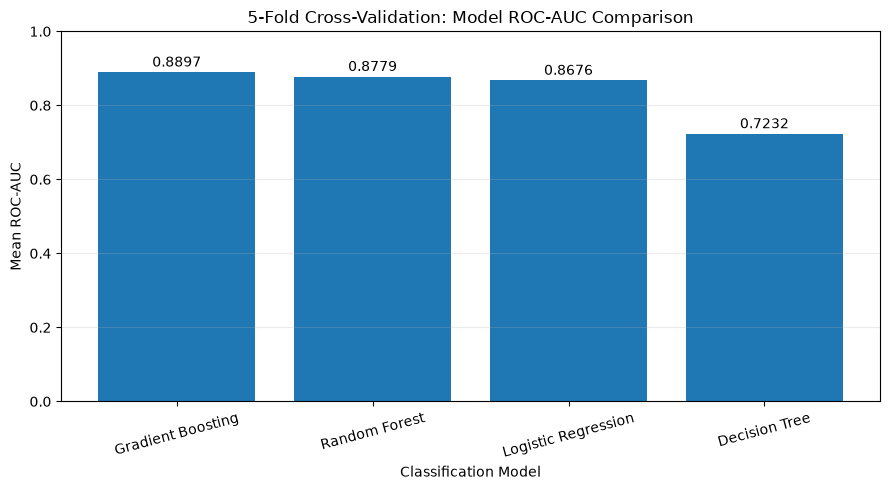

In [68]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["ROC_AUC"]
)

plt.title("5-Fold Cross-Validation: Model ROC-AUC Comparison")
plt.xlabel("Classification Model")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.015,
        f"{height:.4f}",
        ha="center"
    )

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [69]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Build the selected model pipeline
best_model = Pipeline([
    ("income_imputer", EmploymentIncomeImputer()),
    ("feature_engineer", CreditFeatureEngineer()),
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

# Train using training data only
best_model.fit(X_train, y_train)

# Evaluate on held-out test data
y_pred_gb = best_model.predict(X_test)
y_prob_gb = best_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting — Test Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print("Decline Precision:", round(precision_score(y_test, y_pred_gb), 4))
print("Decline Recall:", round(recall_score(y_test, y_pred_gb), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_gb), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["Approved", "Declined"]
))


Gradient Boosting — Test Results
-----------------------------------
Accuracy: 0.8029
Decline Precision: 0.8166
Decline Recall: 0.7493
ROC-AUC: 0.8853

Confusion Matrix:
[[1081  190]
 [ 283  846]]

Classification Report:
              precision    recall  f1-score   support

    Approved       0.79      0.85      0.82      1271
    Declined       0.82      0.75      0.78      1129

    accuracy                           0.80      2400
   macro avg       0.80      0.80      0.80      2400
weighted avg       0.80      0.80      0.80      2400



,Feature,Importance
4,num__delinquencies_24m,0.304419
1,num__credit_score,0.289891
2,num__foir,0.286668
6,num__years_in_current_job,0.027401
22,binary__is_ntc,0.020357
9,cat__employment_type_Gig / Contract,0.018546
3,num__loan_to_income,0.015714
10,cat__employment_type_Salaried,0.015238


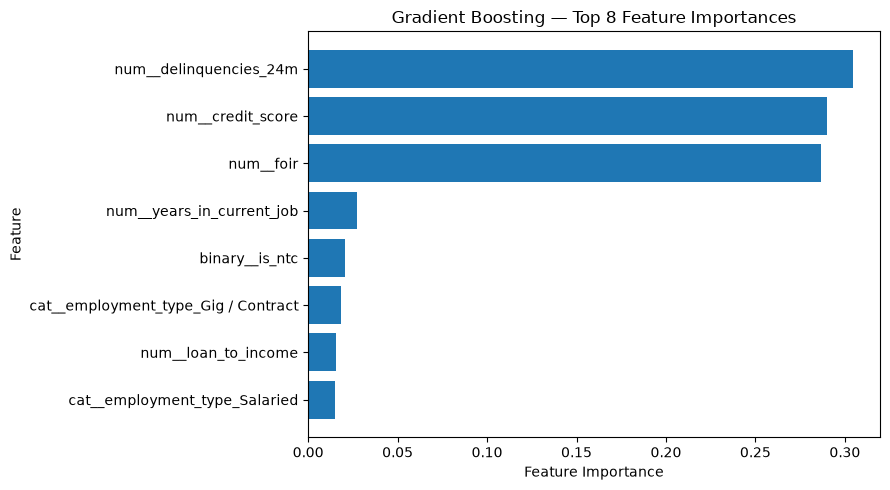

In [70]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract trained Gradient Boosting components
gb_classifier = best_model.named_steps["classifier"]
gb_preprocessor = best_model.named_steps["preprocessor"]

feature_names = gb_preprocessor.get_feature_names_out()
importances = gb_classifier.feature_importances_

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

top_8 = importance_df.head(8)

display(top_8)

# Plot top eight features
plt.figure(figsize=(9, 5))

plt.barh(
    top_8["Feature"][::-1],
    top_8["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting — Top 8 Feature Importances")

plt.tight_layout()
plt.show()


### Step 5.9 — Model Comparison and Selection

Four classification algorithms were evaluated using five-fold stratified cross-validation on the training dataset. **Gradient Boosting achieved the highest mean ROC-AUC (0.8897)**, outperforming Random Forest (0.8779), Logistic Regression (0.8676), and Decision Tree (0.7232).

Gradient Boosting was selected as the candidate model because it demonstrated stronger discrimination and higher decline precision. On the held-out test set, it achieved **80.29% accuracy, 81.66% decline precision, 74.93% decline recall, and 0.8853 ROC-AUC**.

Its three most influential features were **recent delinquencies, credit score, and FOIR**, consistent with our earlier EDA findings that repayment behaviour, credit history, and affordability are strongly associated with historical decisions.

Although Gradient Boosting is less transparent than Logistic Regression, its predictive improvement makes it worth evaluating for selective automation. However, the improvement is modest, and its suitability ultimately depends on whether it improves safe automation coverage under the 5% historical-disagreement constraint. Built-in feature importances describe contributions to tree splitting, not causal effects or the direction of each feature's influence.

In [71]:

import numpy as np
import pandas as pd

# Confirm class order before extracting probabilities
print("Logistic classes:",
      logistic_model.named_steps["classifier"].classes_)

print("Gradient Boosting classes:",
      best_model.named_steps["classifier"].classes_)

# Index of Approved = 0 in each model
lr_approved_idx = list(
    logistic_model.named_steps["classifier"].classes_
).index(0)

gb_approved_idx = list(
    best_model.named_steps["classifier"].classes_
).index(0)

# Approval probabilities on held-out test applications
p_approve_lr = logistic_model.predict_proba(X_test)[:, lr_approved_idx]
p_approve_gb = best_model.predict_proba(X_test)[:, gb_approved_idx]

print("\nLogistic Regression approval probabilities:")
print(np.round(p_approve_lr[:5], 4))

print("\nGradient Boosting approval probabilities:")
print(np.round(p_approve_gb[:5], 4))

print("\nNumber of applications:", len(p_approve_gb))


Logistic classes: [0 1]
Gradient Boosting classes: [0 1]

Logistic Regression approval probabilities:
[0.8572 0.1845 0.6273 0.1895 0.8566]

Gradient Boosting approval probabilities:
[0.9064 0.2706 0.6062 0.3564 0.9401]

Number of applications: 2400


In [72]:

import numpy as np
import pandas as pd

def search_two_lane_thresholds(prob_approve, actual_y):
    actual_y = np.asarray(actual_y)

    # Search a grid of approval probability thresholds
    thresholds = np.round(
        np.arange(0.01, 1.00, 0.01), 2
    )

    results = []

    for low in thresholds:
        for high in thresholds:

            if low >= high:
                continue

            # Separate automated lanes
            auto_decline = prob_approve < low
            fast_track = prob_approve > high

            n_decline = auto_decline.sum()
            n_approve = fast_track.sum()

            # Require both automated lanes to be nonempty
            if n_decline == 0 or n_approve == 0:
                continue

            # Wrongly auto-declined: historically Approved (0)
            decline_errors = (
                auto_decline & (actual_y == 0)
            ).sum()

            # Wrongly fast-tracked: historically Declined (1)
            approval_errors = (
                fast_track & (actual_y == 1)
            ).sum()

            decline_error_rate = decline_errors / n_decline
            approval_error_rate = approval_errors / n_approve

            if (
                decline_error_rate <= 0.05
                and approval_error_rate <= 0.05
            ):
                results.append({
                    "Low_Threshold": low,
                    "High_Threshold": high,
                    "Auto_Decline": n_decline,
                    "Fast_Track": n_approve,
                    "Manual_Review": (
                        len(actual_y) - n_decline - n_approve
                    ),
                    "Decline_Error_%": round(
                        decline_error_rate * 100, 2
                    ),
                    "Approval_Error_%": round(
                        approval_error_rate * 100, 2
                    ),
                    "Automation_%": round(
                        (n_decline + n_approve)
                        / len(actual_y) * 100, 2
                    )
                })

    if not results:
        return pd.DataFrame()

    return (
        pd.DataFrame(results)
        .sort_values(
            ["Automation_%", "Low_Threshold"],
            ascending=[False, False]
        )
        .reset_index(drop=True)
    )


# Search for both models
lr_threshold_results = search_two_lane_thresholds(
    p_approve_lr, y_test
)

gb_threshold_results = search_two_lane_thresholds(
    p_approve_gb, y_test
)

print("Best Logistic Regression threshold pair:")
display(lr_threshold_results.head(1))

print("Best Gradient Boosting threshold pair:")
display(gb_threshold_results.head(1))


Best Logistic Regression threshold pair:


,Low_Threshold,High_Threshold,Auto_Decline,Fast_Track,Manual_Review,Decline_Error_%,Approval_Error_%,Automation_%
0,0.1,0.9,360,378,1662,4.44,4.5,30.75


Best Gradient Boosting threshold pair:


,Low_Threshold,High_Threshold,Auto_Decline,Fast_Track,Manual_Review,Decline_Error_%,Approval_Error_%,Automation_%
0,0.18,0.89,602,459,1339,4.98,4.79,44.21


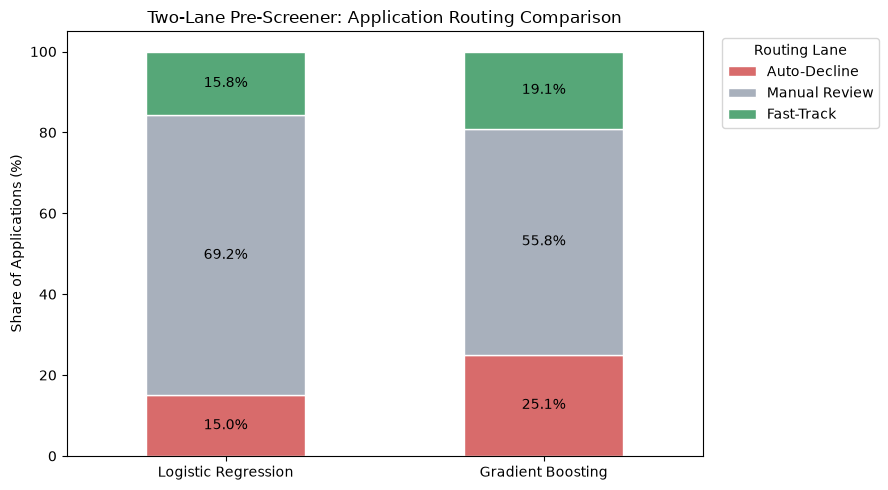

In [73]:

import matplotlib.pyplot as plt
import pandas as pd

lr_best = lr_threshold_results.iloc[0]
gb_best = gb_threshold_results.iloc[0]

routing_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Gradient Boosting"],
    "Auto-Decline": [
        lr_best["Auto_Decline"] / 2400 * 100,
        gb_best["Auto_Decline"] / 2400 * 100
    ],
    "Manual Review": [
        lr_best["Manual_Review"] / 2400 * 100,
        gb_best["Manual_Review"] / 2400 * 100
    ],
    "Fast-Track": [
        lr_best["Fast_Track"] / 2400 * 100,
        gb_best["Fast_Track"] / 2400 * 100
    ]
}).set_index("Model")

ax = routing_df.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#D86B6B", "#A8B0BC", "#56A778"],
    edgecolor="white"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        fontsize=10
    )

plt.title("Two-Lane Pre-Screener: Application Routing Comparison")
plt.ylabel("Share of Applications (%)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.legend(title="Routing Lane", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


### Step 5.10 — Two-Lane Pre-Screening Strategy

A two-lane pre-screening system was designed using predicted approval probabilities. Applications below the low threshold enter the auto-decline lane, applications above the high threshold qualify for fast-track approval with a light-touch check, and all remaining applications receive manual analyst review.

**Gradient Boosting was the stronger candidate**, with approval-probability thresholds of **0.18 (auto-decline)** and **0.89 (fast-track)**. It routed 25.08% of applications to auto-decline, 19.13% to fast-track approval, and 55.79% to manual review. Historical disagreement was 4.98% in the decline lane and 4.79% in the approval lane, both within the 5% limit on the evaluated sample.

Logistic Regression achieved 30.75% total automation, compared with **44.21% for Gradient Boosting**. At 3,000 monthly applications and 25 minutes per full review, Gradient Boosting could avoid approximately **1,326 full reviews (552.6 analyst hours)** monthly, compared with **923 reviews (384.4 hours)** under Logistic Regression — an additional **approximately 404 applications and 168 analyst hours**.

**Limitation:** These thresholds were optimized on the test data, so the observed error rates may be optimistic. Thresholds should be selected using separate validation data and confirmed on an untouched test set before deployment. Fast-track applications also require light-touch review, so net time savings may be lower.

## Step 5.11 — Credit Policy Recommendation

**To: Head of Retail Lending**

I recommend **Gradient Boosting as the preferred candidate** for the credit pre-screening engine because it achieved the highest cross-validated ROC-AUC (0.8897) among the four evaluated models.

Using predicted approval probabilities, applications below **0.18** would qualify for auto-decline (25.08%), those above **0.89** for fast-track approval with a light-touch check (19.13%), and the remaining **55.79%** would receive manual review.

At 3,000 applications per month, this could remove approximately **1,326 applications from full manual review**, saving up to **553 gross analyst review-hours**, compared with approximately **923 applications and 384 hours** under Logistic Regression.

Both Gradient Boosting automated lanes met the 5% historical-disagreement requirement in the evaluated sample, but thresholds were selected using that same test data, creating an important risk of optimistic performance estimates.

Borderline applications, unusual or unverified income records, and applicants whose credit information requires clarification should remain subject to human review.

Our initial gender fairness audit identified relatively small auto-decline disparities, but the bank should monitor approval rates, lane-specific errors, and outcomes across demographic and employment groups after launch.

Before full rollout, I recommend selecting thresholds using separate validation data, testing the locked system on a fresh time-based sample, and conducting a controlled pilot with human oversight before allowing automated decisions.

In [75]:


import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Reuse fitted transformations from Gradient Boosting pipeline
income_imputer = best_model.named_steps["income_imputer"]
feature_engineer = best_model.named_steps["feature_engineer"]

# Apply the same trained transformations to train and test
train_features = feature_engineer.transform(
    income_imputer.transform(X_train)
)

test_features = feature_engineer.transform(
    income_imputer.transform(X_test)
)

cluster_columns = [
    "monthly_income",
    "credit_score",
    "foir",
    "years_in_current_job",
    "age"
]

X_cluster_train = train_features[cluster_columns]
X_cluster_test = test_features[cluster_columns]

# Learn clustering preprocessing from training data only
cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()

X_cluster_train_scaled = cluster_scaler.fit_transform(
    cluster_imputer.fit_transform(X_cluster_train)
)

X_cluster_scaled = cluster_scaler.transform(
    cluster_imputer.transform(X_cluster_test)
)

print("Training shape:", X_cluster_train_scaled.shape)
print("Test shape:", X_cluster_scaled.shape)
print("Missing values:", np.isnan(X_cluster_scaled).sum())


Training shape: (9600, 5)
Test shape: (2400, 5)
Missing values: 0


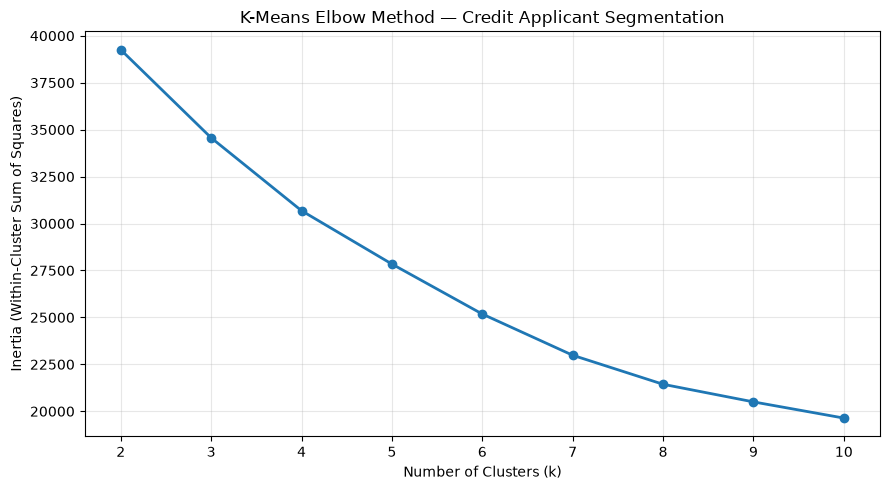

In [76]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_train_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o",
    linewidth=2
)

plt.title("K-Means Elbow Method — Credit Applicant Segmentation")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [77]:

from sklearn.cluster import KMeans
import pandas as pd

# Select number of clusters from elbow plot
optimal_k = 7

# Train K-Means on training data only
kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_final.fit(X_cluster_train_scaled)

# Assign clusters to test applications
test_clusters = kmeans_final.predict(X_cluster_scaled)

# Create cluster profiling dataset
cluster_profile_df = X_cluster_test.copy()
cluster_profile_df["Cluster"] = test_clusters

# Summarize each cluster
cluster_summary = (
    cluster_profile_df.groupby("Cluster")
    .agg(
        Applicants=("Cluster", "size"),
        Median_Income=("monthly_income", "median"),
        Median_Credit_Score=("credit_score", "median"),
        Median_FOIR=("foir", "median"),
        Median_Job_Years=("years_in_current_job", "median"),
        Median_Age=("age", "median")
    )
    .round(2)
)

display(cluster_summary)


,Applicants,Median_Income,Median_Credit_Score,Median_FOIR,Median_Job_Years,Median_Age
Cluster,,,,,,
0,609,43500.0,738.0,0.29,1.9,26.0
1,268,48000.0,728.0,0.72,2.7,32.0
2,526,46500.0,664.0,0.32,2.7,33.0
3,237,56000.0,731.0,0.32,9.6,39.0
4,177,128000.0,719.0,0.30,3.2,36.0
5,4,1101000.0,718.0,0.03,3.2,37.0
6,579,50500.0,775.5,0.30,3.3,37.0


In [78]:

# Build evaluation dataset for test applicants
cluster_evaluation = cluster_profile_df.copy()

# Historical decisions: 0 = Approved, 1 = Declined
cluster_evaluation["Actual_Declined"] = y_test.to_numpy()

# Gradient Boosting predictions at default 0.50 threshold
cluster_evaluation["Predicted_Declined"] = y_pred_gb

# Whether each prediction disagrees with the historical decision
cluster_evaluation["Prediction_Error"] = (
    cluster_evaluation["Actual_Declined"]
    != cluster_evaluation["Predicted_Declined"]
)

# Group-level evaluation
cluster_performance = (
    cluster_evaluation.groupby("Cluster")
    .agg(
        Applicants=("Cluster", "size"),
        Approval_Rate=(
            "Actual_Declined",
            lambda x: (x == 0).mean() * 100
        ),
        Model_Error_Rate=(
            "Prediction_Error",
            lambda x: x.mean() * 100
        ),
        Incorrect_Predictions=(
            "Prediction_Error", "sum"
        )
    )
    .round(2)
)

display(cluster_performance)


,Applicants,Approval_Rate,Model_Error_Rate,Incorrect_Predictions
Cluster,,,,
0,609,63.22,22.66,138
1,268,15.30,12.69,34
2,526,28.71,18.25,96
3,237,60.34,18.14,43
4,177,61.02,24.86,44
5,4,50.00,25.00,1
6,579,76.17,20.21,117


### Step 5.12 — K-Means Applicant Segmentation

K-Means clustering was performed using monthly income, credit score, FOIR, years in the current job, and age. Based on the elbow analysis, seven applicant segments were selected and profiled using historical approval rates and Gradient Boosting classification errors.

**Cluster 4 (Higher-Income Applicants)** had a 24.86% classification error rate across 177 applicants, making it an important segment for further model improvement. **Cluster 0 (Young, Moderate-Affordability Applicants)** contributed the largest number of incorrect predictions (138), indicating substantial potential impact from improved modelling.

**Cluster 5 (Extreme-Income Verification Group)** contained only four test applicants, with a median declared monthly income of ₹11.01 lakh and a median FOIR of 3%. Although its observed error rate was 25%, the sample is too small for a reliable comparison.

Applications with unusually high or unverified income values should remain under **mandatory human review**, as possible income-entry inconsistencies could distort affordability features and automated decisions.

**Conclusion:** Segmentation helps identify populations requiring data verification or additional model analysis. Cluster labels were not included as classifier inputs, preventing the exploratory segmentation from directly changing credit predictions.

In [79]:

print("Training data:", X_train.shape, y_train.shape)
print("Test data:", X_test.shape, y_test.shape)

print("CV folds:", cv.n_splits)

print("Selected classifier:",
      best_model.named_steps["classifier"].__class__.__name__)

print("Training feature names:",
      X_train.columns.tolist())


Training data: (9600, 14) (9600,)
Test data: (2400, 14) (2400,)
CV folds: 5
Selected classifier: GradientBoostingClassifier
Training feature names: ['age', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi']


In [80]:

import numpy as np
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Generate training-only out-of-fold probabilities
gb_oof_proba = cross_val_predict(
    estimator=clone(best_model),
    X=X_train,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

# Approved = 0, Declined = 1
p_approve_gb_oof = gb_oof_proba[:, 0]

print("OOF probability shape:", p_approve_gb_oof.shape)
print("Minimum probability:", round(p_approve_gb_oof.min(), 4))
print("Maximum probability:", round(p_approve_gb_oof.max(), 4))
print("Missing probabilities:", np.isnan(p_approve_gb_oof).sum())

print("\nFirst 5 approval probabilities:")
print(np.round(p_approve_gb_oof[:5], 4))


OOF probability shape: (9600,)
Minimum probability: 0.0051
Maximum probability: 0.9792
Missing probabilities: 0

First 5 approval probabilities:
[0.974  0.6748 0.8161 0.0255 0.3183]


In [81]:

# Search thresholds using training-only OOF predictions
gb_oof_threshold_results = search_two_lane_thresholds(
    p_approve_gb_oof,
    y_train
)

if gb_oof_threshold_results.empty:
    print("No threshold pair satisfied both 5% limits.")
else:
    print("Best thresholds selected from OOF predictions:")
    display(gb_oof_threshold_results.head(1))

    # Save selected thresholds
    selected_low = gb_oof_threshold_results.iloc[0]["Low_Threshold"]
    selected_high = gb_oof_threshold_results.iloc[0]["High_Threshold"]

    print(f"\nSelected low threshold: {selected_low:.2f}")
    print(f"Selected high threshold: {selected_high:.2f}")


Best thresholds selected from OOF predictions:


,Low_Threshold,High_Threshold,Auto_Decline,Fast_Track,Manual_Review,Decline_Error_%,Approval_Error_%,Automation_%
0,0.15,0.88,2131,1992,5477,4.74,4.72,42.95



Selected low threshold: 0.15
Selected high threshold: 0.88


In [82]:

import numpy as np
import pandas as pd

# Locked thresholds chosen using training-only OOF predictions
low = selected_low
high = selected_high

# Final fitted Gradient Boosting model's test probabilities
p_test = best_model.predict_proba(X_test)[:, 0]
actual = y_test.to_numpy()

# Route each application
auto_decline = p_test < low
fast_track = p_test > high
manual_review = ~(auto_decline | fast_track)

n_decline = int(auto_decline.sum())
n_fast = int(fast_track.sum())
n_manual = int(manual_review.sum())

# Historical disagreement in each automated lane
wrong_declines = int((auto_decline & (actual == 0)).sum())
wrong_fast_tracks = int((fast_track & (actual == 1)).sum())

decline_error = (
    wrong_declines / n_decline if n_decline else np.nan
)
fast_track_error = (
    wrong_fast_tracks / n_fast if n_fast else np.nan
)

test_audit = pd.DataFrame([{
    "Low_Threshold": low,
    "High_Threshold": high,
    "Auto_Decline": n_decline,
    "Fast_Track": n_fast,
    "Manual_Review": n_manual,
    "Wrong_Declines": wrong_declines,
    "Wrong_Fast_Tracks": wrong_fast_tracks,
    "Decline_Error_%": round(decline_error * 100, 2),
    "Fast_Track_Error_%": round(fast_track_error * 100, 2),
    "Automation_%": round(
        (n_decline + n_fast) / len(actual) * 100, 2
    ),
    "Both_Lanes_Pass": (
        n_decline > 0
        and n_fast > 0
        and decline_error <= 0.05
        and fast_track_error <= 0.05
    )
}])

display(test_audit)


,Low_Threshold,High_Threshold,Auto_Decline,Fast_Track,Manual_Review,Wrong_Declines,Wrong_Fast_Tracks,Decline_Error_%,Fast_Track_Error_%,Automation_%,Both_Lanes_Pass
0,0.15,0.88,546,486,1368,23,25,4.21,5.14,43.0,False


In [83]:

validation_result = gb_oof_threshold_results.iloc[0]
test_result = test_audit.iloc[0]

audit_comparison = pd.DataFrame({
    "Metric": [
        "Low Threshold",
        "High Threshold",
        "Auto-Decline Error (%)",
        "Fast-Track Error (%)",
        "Automation Coverage (%)"
    ],
    "OOF Validation": [
        validation_result["Low_Threshold"],
        validation_result["High_Threshold"],
        validation_result["Decline_Error_%"],
        validation_result["Approval_Error_%"],
        validation_result["Automation_%"]
    ],
    "Held-Out Test": [
        test_result["Low_Threshold"],
        test_result["High_Threshold"],
        test_result["Decline_Error_%"],
        test_result["Fast_Track_Error_%"],
        test_result["Automation_%"]
    ]
})

display(audit_comparison)


,Metric,OOF Validation,Held-Out Test
0,Low Threshold,0.15,0.15
1,High Threshold,0.88,0.88
2,Auto-Decline Error (%),4.74,4.21
3,Fast-Track Error (%),4.72,5.14
4,Automation Coverage (%),42.95,43.00


### Final Validation Audit — Revised Credit Policy Recommendation

Gradient Boosting remains the preferred candidate based on its cross-validated ROC-AUC of **0.8897** and stronger predictive performance relative to Logistic Regression.

Using training-only out-of-fold predictions, approval-probability thresholds of **0.15 for auto-decline** and **0.88 for fast-track approval** were selected, yielding 42.95% estimated automation coverage during validation.

On the held-out test split, automation coverage was **43.00%**, with 546 applications routed to auto-decline, 486 to fast-track approval, and 1,368 to manual review.

The auto-decline lane met the 5% historical-disagreement requirement at **4.21%**, but the fast-track lane exceeded the limit at **5.14%**, meaning the proposed two-lane configuration does not fully satisfy the bank's risk appetite.

Therefore, the bank should **not deploy both automated lanes under the current configuration**; the fast-track lane should remain under human review until additional validation supports a compliant threshold.

The model's performance should be monitored across demographic and employment groups, with unusual income records and uncertain applications referred for human verification.

Before rollout, the bank should conduct fresh time-based validation, reassess threshold stability and calibration, and complete a controlled pilot with human oversight.



In [84]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
import numpy as np

# Generate out-of-fold probabilities for Logistic Regression
lr_oof_proba = cross_val_predict(
    estimator=clone(logistic_model),
    X=X_train,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

# Probability of Approved (class 0)
p_approve_lr_oof = lr_oof_proba[:, 0]

# Optimize thresholds using training-only OOF predictions
lr_oof_threshold_results = search_two_lane_thresholds(
    p_approve_lr_oof,
    y_train
)

print("Logistic Regression — OOF Threshold Selection")

if lr_oof_threshold_results.empty:
    print("No threshold pair satisfies both 5% limits.")
else:
    display(lr_oof_threshold_results.head(1))

    lr_selected_low = lr_oof_threshold_results.iloc[0]["Low_Threshold"]
    lr_selected_high = lr_oof_threshold_results.iloc[0]["High_Threshold"]

    print(f"Selected low threshold: {lr_selected_low:.2f}")
    print(f"Selected high threshold: {lr_selected_high:.2f}")


Logistic Regression — OOF Threshold Selection


,Low_Threshold,High_Threshold,Auto_Decline,Fast_Track,Manual_Review,Decline_Error_%,Approval_Error_%,Automation_%
0,0.11,0.91,1559,1339,6702,4.75,4.41,30.19


Selected low threshold: 0.11
Selected high threshold: 0.91


In [85]:

import numpy as np
import pandas as pd

# Locked thresholds selected from Logistic Regression OOF predictions
low_lr = lr_selected_low
high_lr = lr_selected_high

# Predict approval probabilities using the fitted Logistic Regression
p_test_lr = logistic_model.predict_proba(X_test)[:, 0]
actual = y_test.to_numpy()

# Apply the routing rules
auto_decline_lr = p_test_lr < low_lr
fast_track_lr = p_test_lr > high_lr
manual_review_lr = ~(auto_decline_lr | fast_track_lr)

n_decline_lr = int(auto_decline_lr.sum())
n_fast_lr = int(fast_track_lr.sum())
n_manual_lr = int(manual_review_lr.sum())

# Historical disagreements
wrong_declines_lr = int(
    (auto_decline_lr & (actual == 0)).sum()
)

wrong_fast_tracks_lr = int(
    (fast_track_lr & (actual == 1)).sum()
)

decline_error_lr = (
    wrong_declines_lr / n_decline_lr
    if n_decline_lr else np.nan
)

fast_track_error_lr = (
    wrong_fast_tracks_lr / n_fast_lr
    if n_fast_lr else np.nan
)

lr_test_audit = pd.DataFrame([{
    "Low_Threshold": low_lr,
    "High_Threshold": high_lr,
    "Auto_Decline": n_decline_lr,
    "Fast_Track": n_fast_lr,
    "Manual_Review": n_manual_lr,
    "Wrong_Declines": wrong_declines_lr,
    "Wrong_Fast_Tracks": wrong_fast_tracks_lr,
    "Decline_Error_%": round(decline_error_lr * 100, 2),
    "Fast_Track_Error_%": round(fast_track_error_lr * 100, 2),
    "Automation_%": round(
        (n_decline_lr + n_fast_lr) / len(actual) * 100, 2
    ),
    "Both_Lanes_Pass": bool(
        n_decline_lr > 0
        and n_fast_lr > 0
        and decline_error_lr <= 0.05
        and fast_track_error_lr <= 0.05
    )
}])

display(lr_test_audit)


,Low_Threshold,High_Threshold,Auto_Decline,Fast_Track,Manual_Review,Wrong_Declines,Wrong_Fast_Tracks,Decline_Error_%,Fast_Track_Error_%,Automation_%,Both_Lanes_Pass
0,0.11,0.91,386,337,1677,21,14,5.44,4.15,30.12,False


### Final Audit — Model Comparison with OOF-Selected Thresholds

Thresholds for Logistic Regression and Gradient Boosting were selected using five-fold out-of-fold predictions from the training set and subsequently evaluated without adjustment on the held-out test split.

**Gradient Boosting** achieved 43.00% automation coverage, with a 4.21% auto-decline disagreement rate and a 5.14% fast-track disagreement rate. **Logistic Regression** achieved 30.12% automation coverage, with a 5.44% auto-decline disagreement rate and a 4.15% fast-track disagreement rate.

Although Gradient Boosting provides substantially greater potential automation coverage, **neither model satisfies the 5% historical-disagreement limit in both lanes simultaneously** on the evaluated test split.

The bank should not deploy either complete two-lane configuration without further validation. The results support continued investigation of Gradient Boosting's auto-decline lane and Logistic Regression's fast-track lane as separate candidates, rather than combining them without additional testing.

Threshold robustness, probability calibration, fairness, and performance on fresh time-based application data should be assessed before operational rollout. Earlier test-set threshold searches were exploratory and must not be interpreted as independent deployment evidence.